# OASIS Brain Mask Inspection

Run this notebook inside `py310sitreg_v1_test1` from `/homebase/code_sync/inrorspline`.

This audit treats raw `image > 0` as the canonical OASIS foreground mask and compares it against `seg > 0` as a label/comparison mask for the seed-3 shuffled first10 OASIS pairs.

In [1]:
from pathlib import Path

REPO = Path('/homebase/code_sync/inrorspline')
PAIR_FILE = REPO / 'configs/splits/oasis/pair_test_200_shuffled_seed000003.txt'
OASIS_ROOT = Path('/database/wavereg/datasets/OASIS/OASIS_official/oasis_organized/split_v1')
OUT_DIR = REPO / 'outputs/data_inspection/oasis_mask_audit_seed3_first10'
REPO, PAIR_FILE.exists(), OASIS_ROOT.exists()

(PosixPath('/homebase/code_sync/inrorspline'), True, True)

In [2]:
!cd /homebase/code_sync/inrorspline && python scripts/data/inspection/oasis_mask_visual_audit.py \
  --pair-file configs/splits/oasis/pair_test_200_shuffled_seed000003.txt \
  --oasis-root /database/wavereg/datasets/OASIS/OASIS_official/oasis_organized/split_v1 \
  --num-pairs 10 \
  --out-dir outputs/data_inspection/oasis_mask_audit_seed3_first10

Wrote 20 subject audits to outputs/data_inspection/oasis_mask_audit_seed3_first10


In [3]:
import pandas as pd

summary_csv = OUT_DIR / 'oasis_mask_visual_audit_summary.csv'
oasis_df = pd.read_csv(summary_csv, dtype={'subject_id': str})
oasis_df.sort_values('dice')[[
    'subject_id',
    'orientation',
    'coronal_fixed_array_axis',
    'coronal_fixed_index',
    'coronal_aspect',
    'foreground_rule',
    'dice',
    'canonical_fg_fraction',
    'seg_label_fg_fraction',
    'seg_label_fg_covered_by_canonical_fg',
    'canonical_fg_covered_by_seg_label_fg',
    'figure',
]]

,subject_id,orientation,coronal_fixed_array_axis,coronal_fixed_index,coronal_aspect,foreground_rule,dice,canonical_fg_fraction,seg_label_fg_fraction,seg_label_fg_covered_by_canonical_fg,canonical_fg_covered_by_seg_label_fg,figure
11,0024,LIA,0,107,1.0,raw image > 0,0.816460,0.303255,0.209266,0.999812,0.689935,outputs/data_inspection/oasis_mask_audit_seed3...
4,0037,LIA,0,108,1.0,raw image > 0,0.818068,0.307503,0.212853,0.999955,0.692167,outputs/data_inspection/oasis_mask_audit_seed3...
6,0117,LIA,0,107,1.0,raw image > 0,0.818842,0.316127,0.219158,0.999995,0.693255,outputs/data_inspection/oasis_mask_audit_seed3...
15,0149,LIA,0,106,1.0,raw image > 0,0.819340,0.298382,0.207070,0.999990,0.693972,outputs/data_inspection/oasis_mask_audit_seed3...
0,0333,LIA,0,106,1.0,raw image > 0,0.821589,0.312769,0.218065,0.999994,0.697204,outputs/data_inspection/oasis_mask_audit_seed3...
2,0113,LIA,0,108,1.0,raw image > 0,0.821934,0.302411,0.211011,0.999946,0.697724,outputs/data_inspection/oasis_mask_audit_seed3...
14,0014,LIA,0,106,1.0,raw image > 0,0.825841,0.282185,0.198511,0.999891,0.703400,outputs/data_inspection/oasis_mask_audit_seed3...
18,0173,LIA,0,107,1.0,raw image > 0,0.825910,0.299076,0.210388,0.999990,0.703452,outputs/data_inspection/oasis_mask_audit_seed3...
12,0194,LIA,0,108,1.0,raw image > 0,0.826518,0.303197,0.213622,0.999803,0.704427,outputs/data_inspection/oasis_mask_audit_seed3...
19,0136,LIA,0,107,1.0,raw image > 0,0.828731,0.301703,0.213475,0.999986,0.707557,outputs/data_inspection/oasis_mask_audit_seed3...


## Figure Review

Each panel shows raw image, canonical foreground `image > 0`, `seg > 0` as a comparator, and overlap/difference in standard coronal view. The display convention is top = patient superior, bottom = patient inferior, screen left = patient right, and screen right = patient left.

### OASIS 0014 | Dice 0.8258

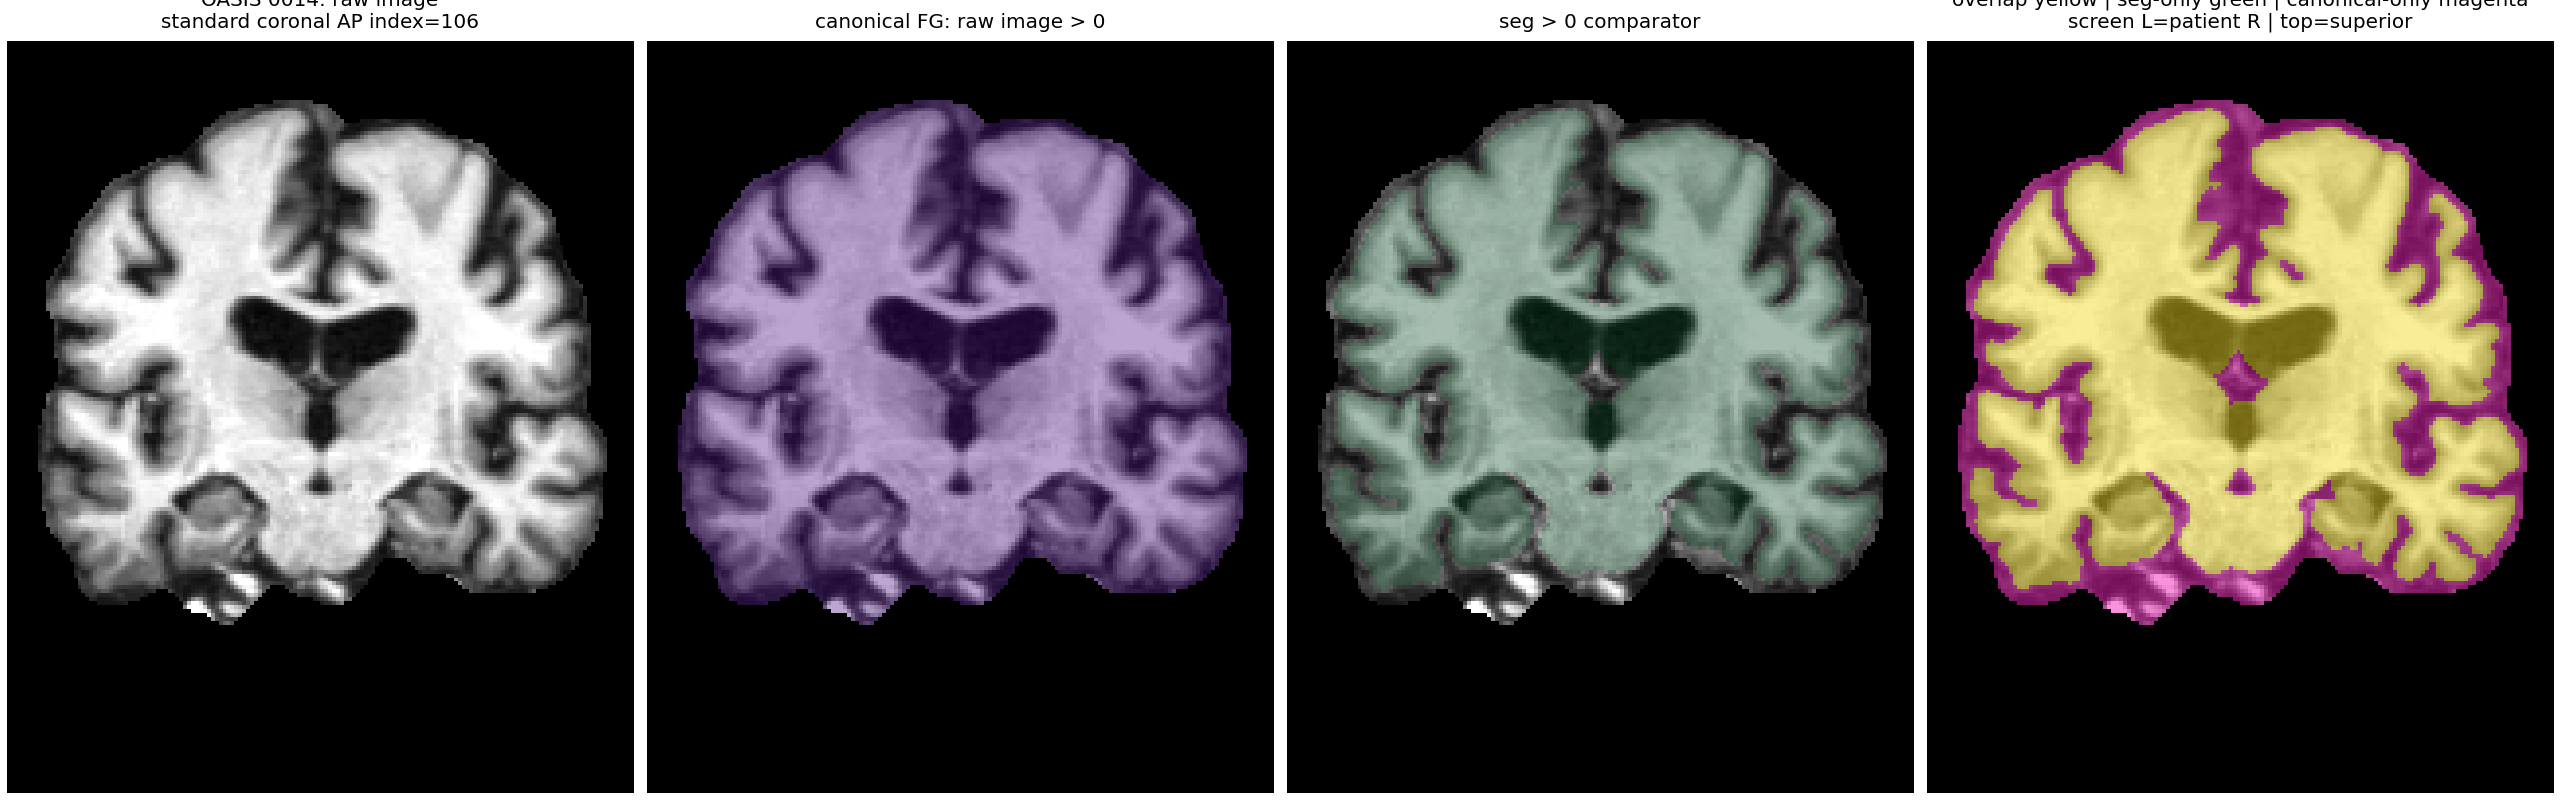

### OASIS 0017 | Dice 0.8372

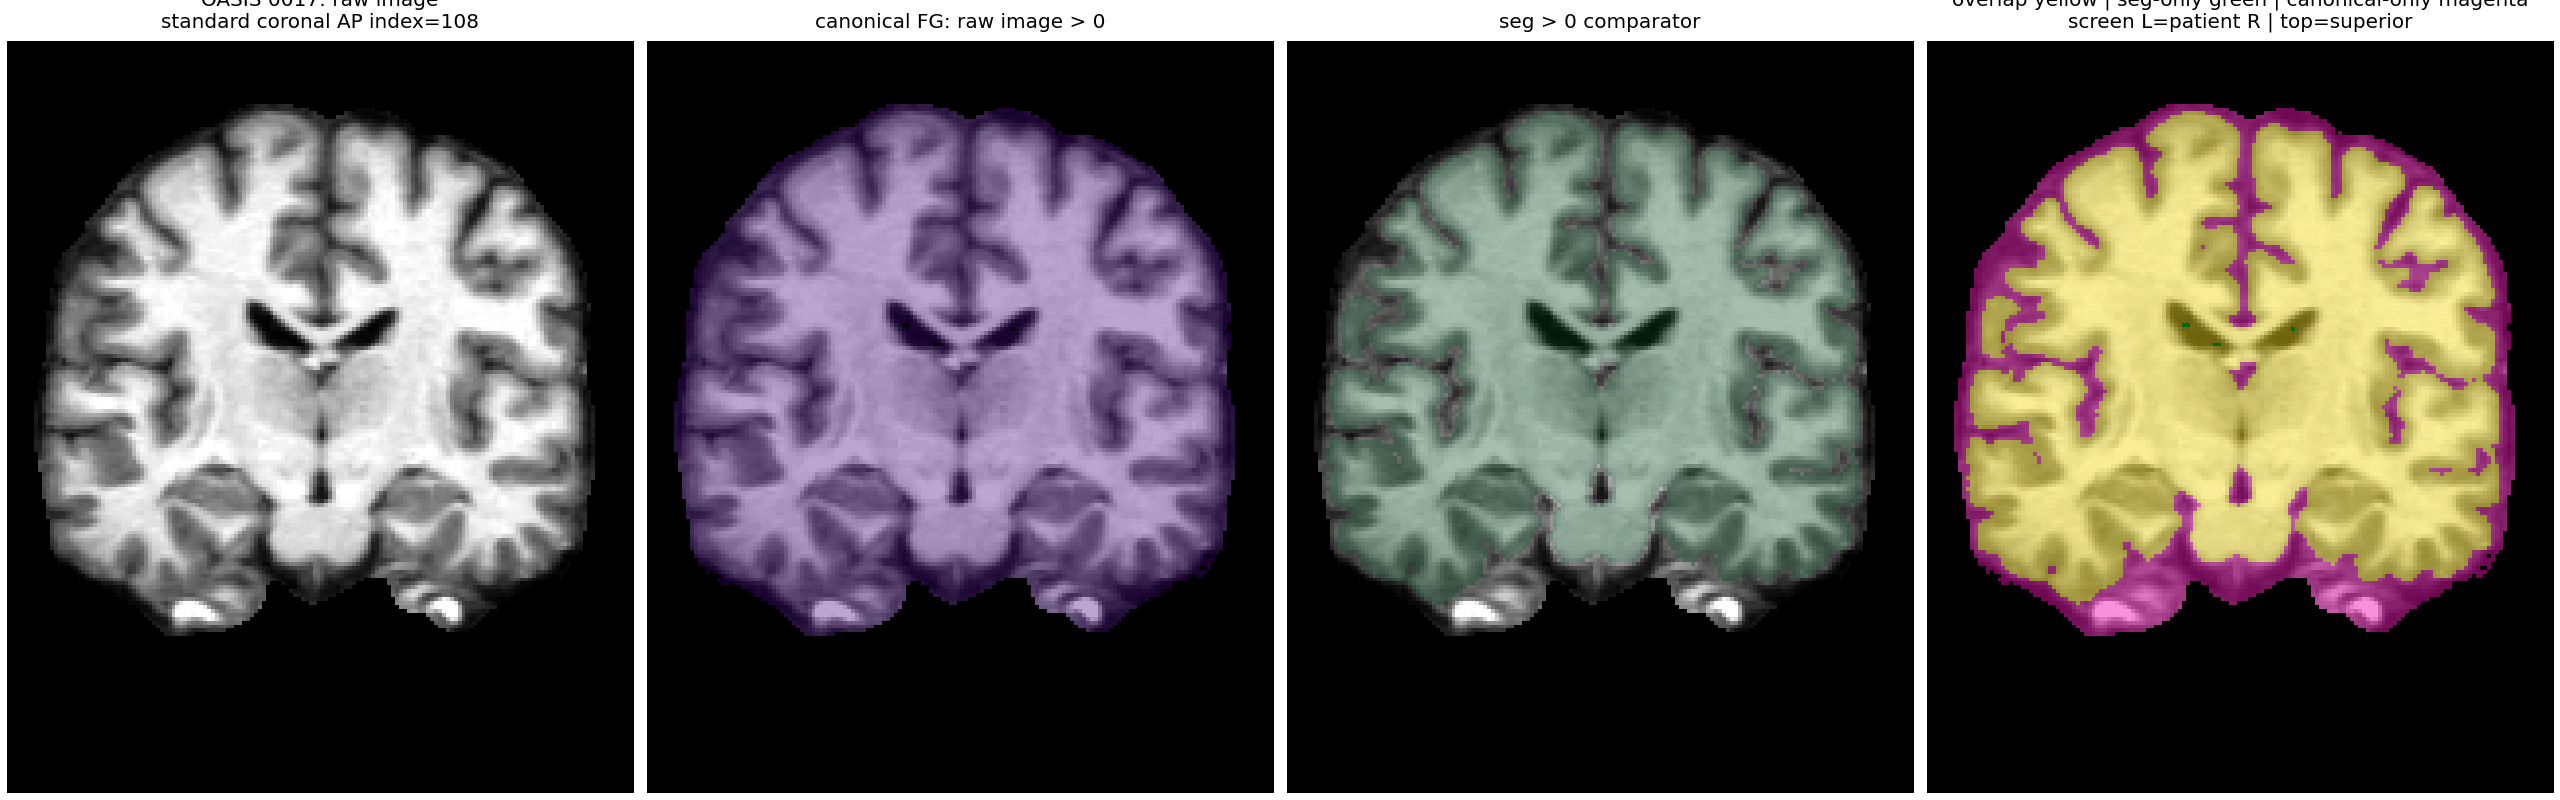

### OASIS 0024 | Dice 0.8165

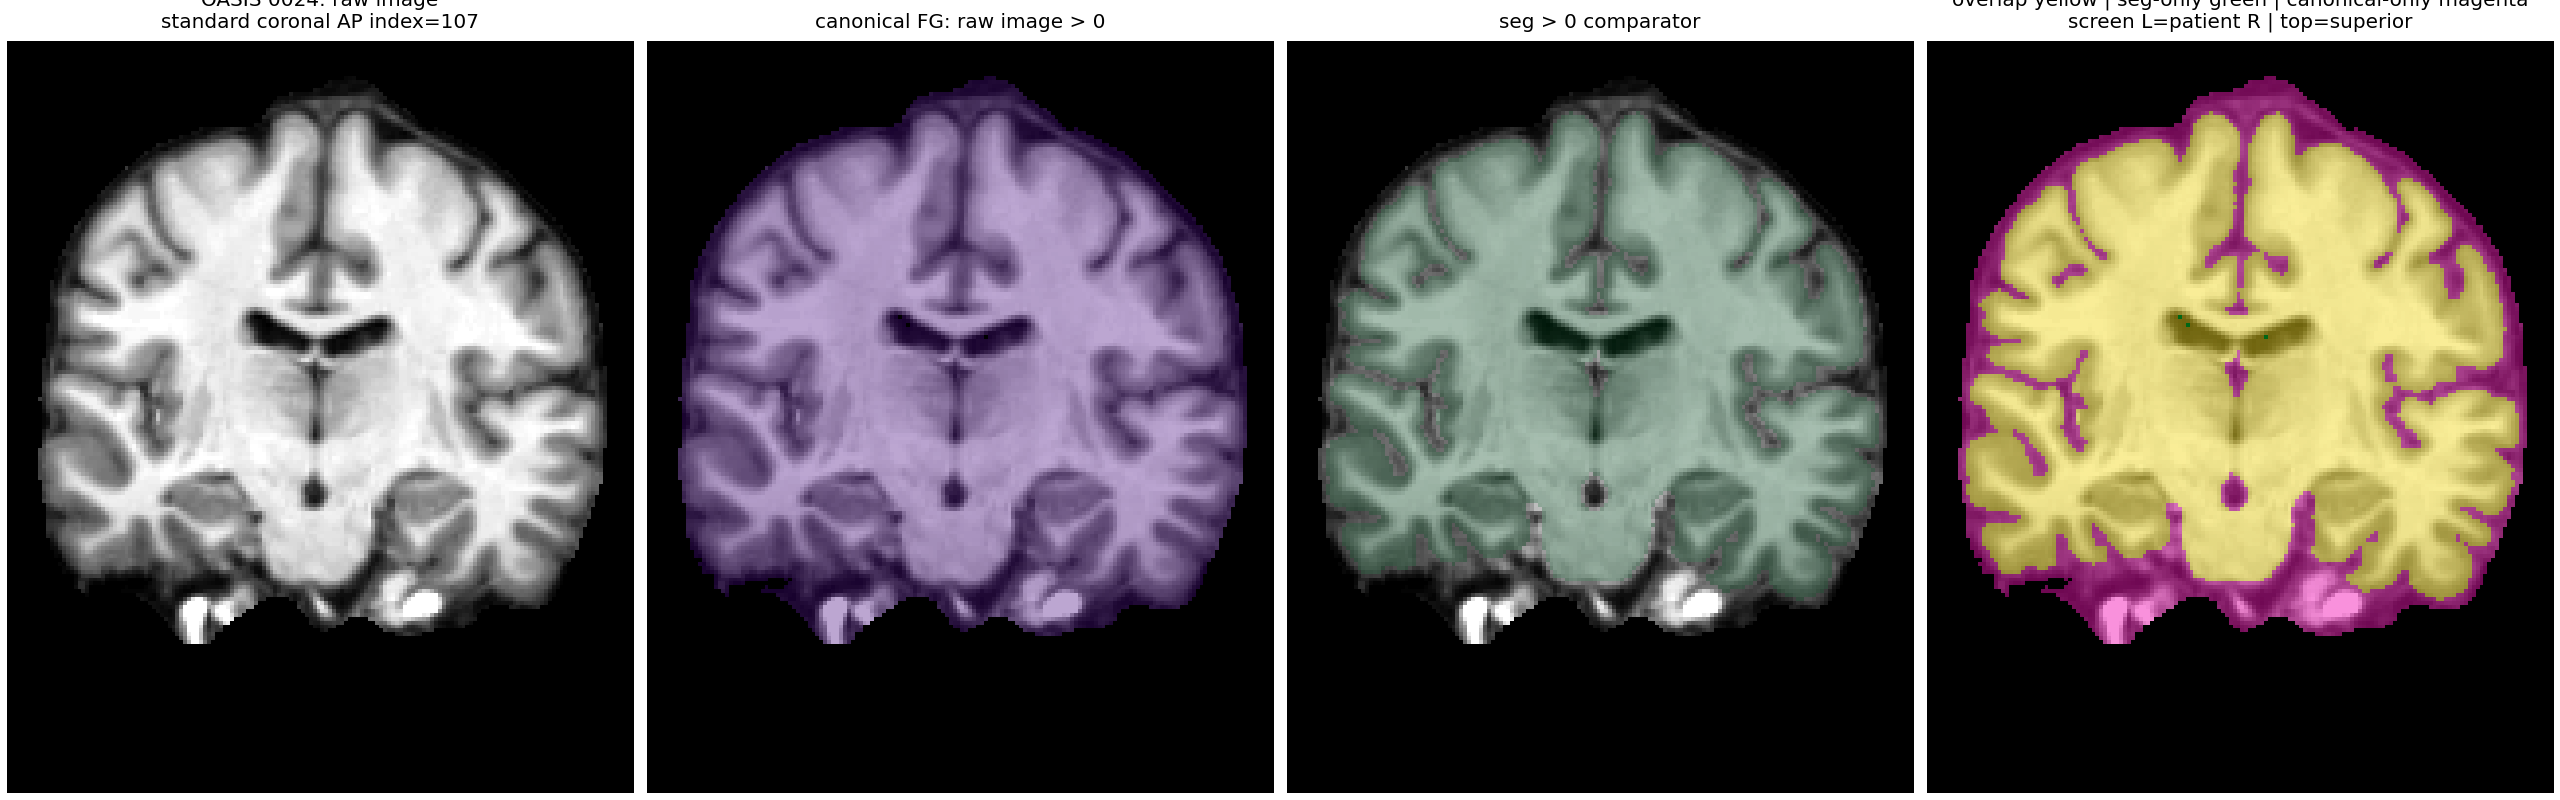

### OASIS 0037 | Dice 0.8181

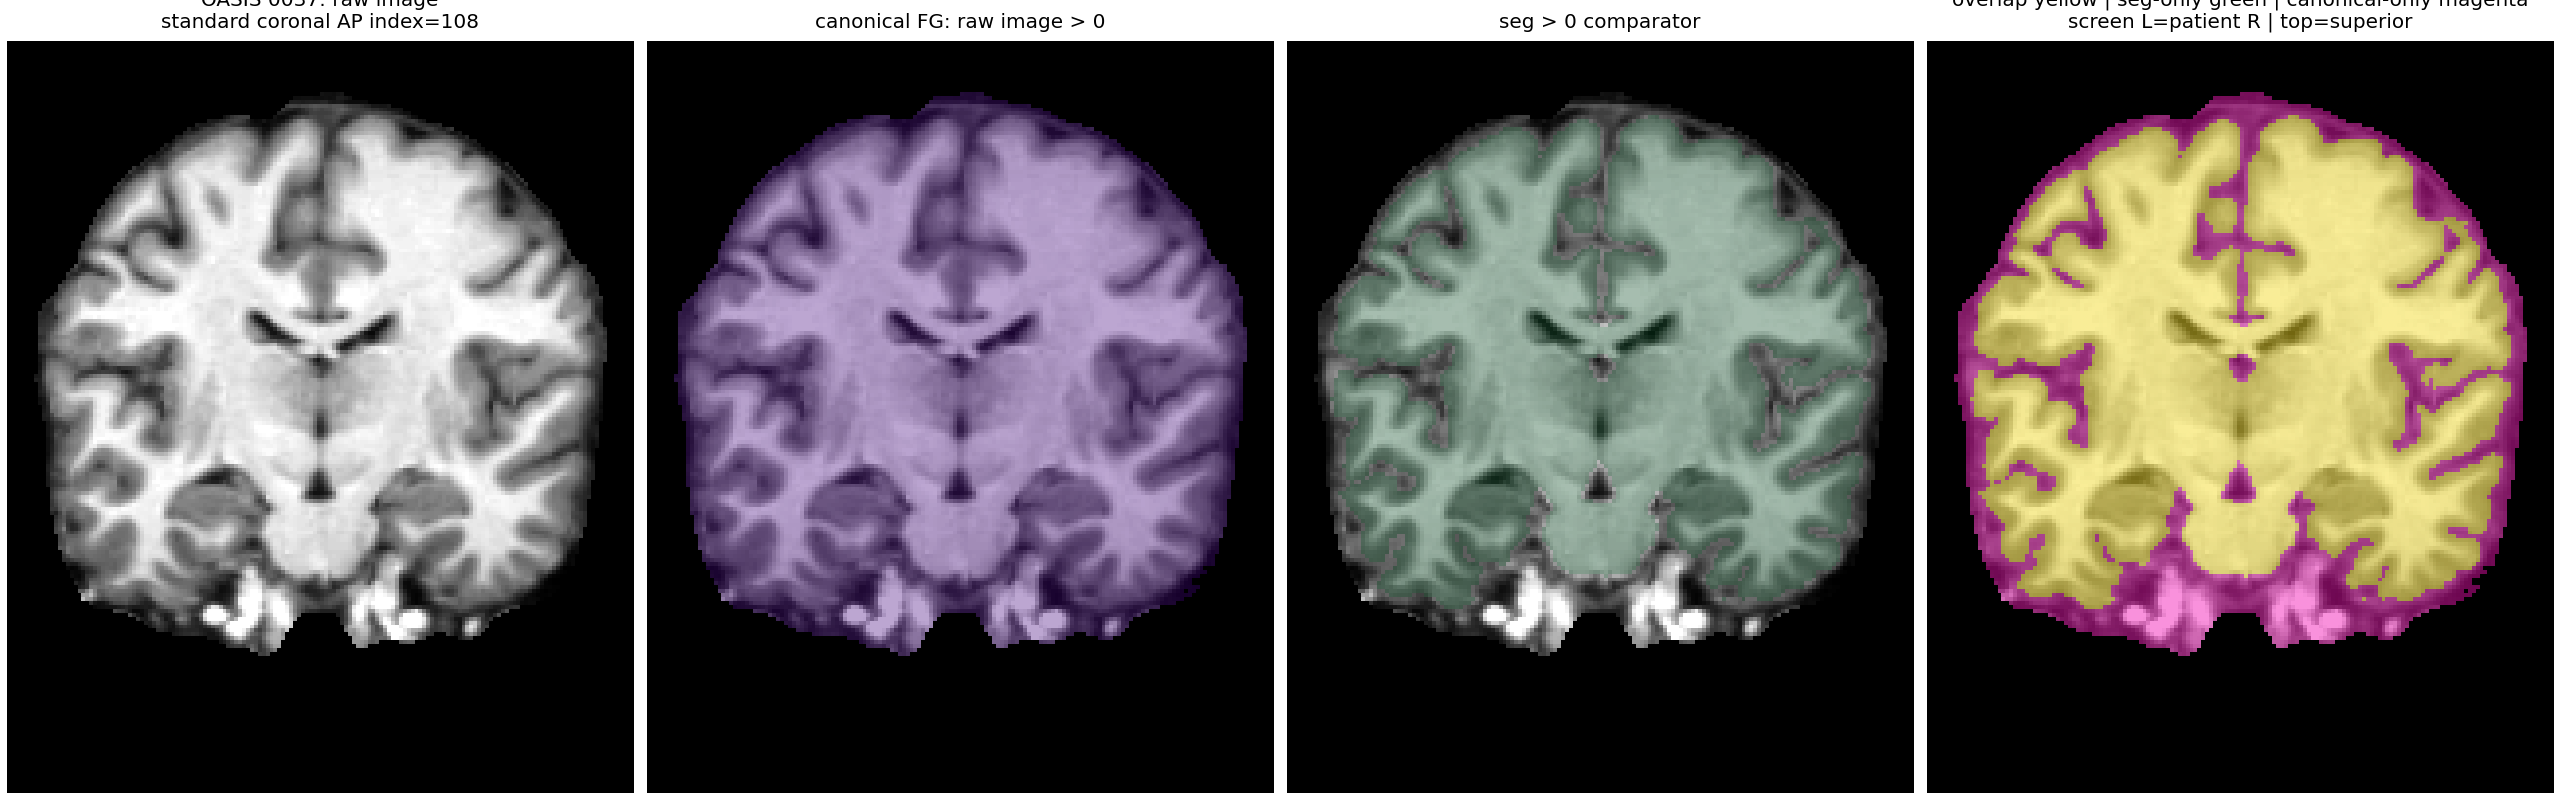

### OASIS 0084 | Dice 0.8546

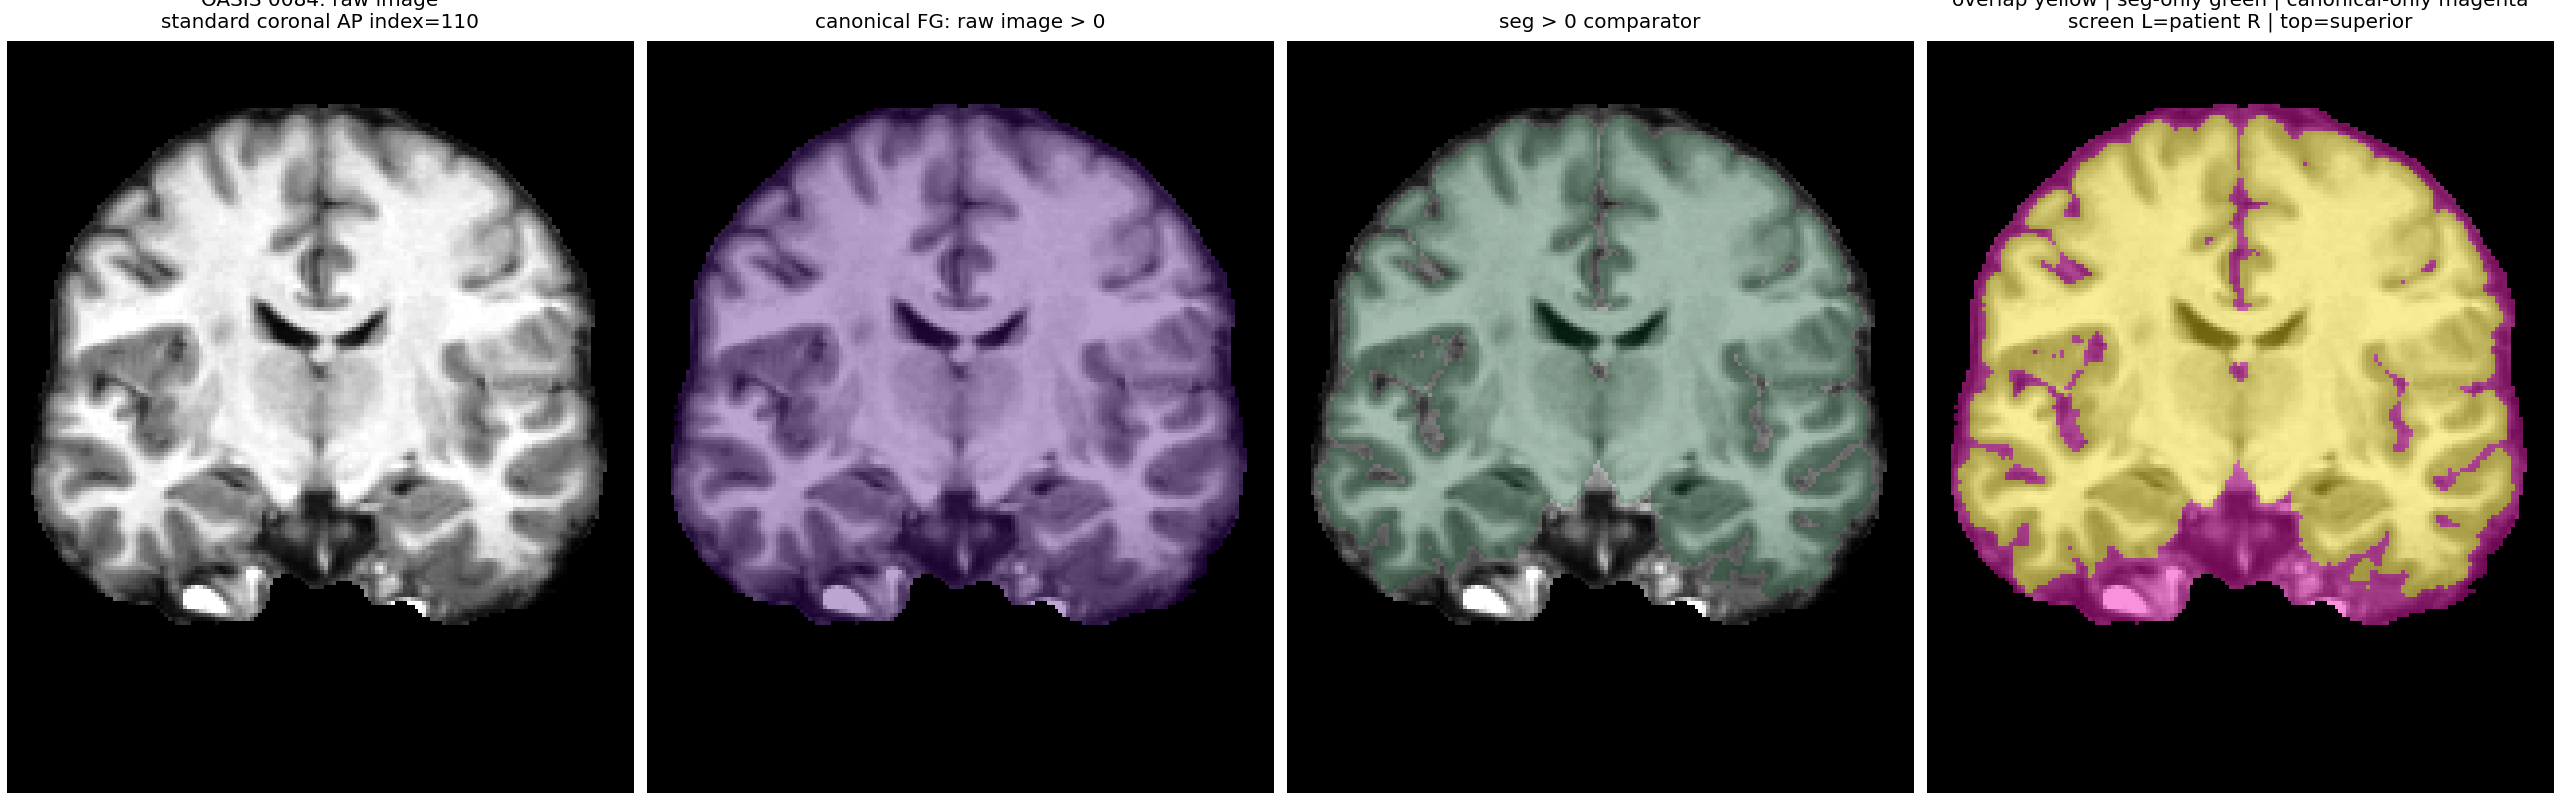

### OASIS 0108 | Dice 0.8379

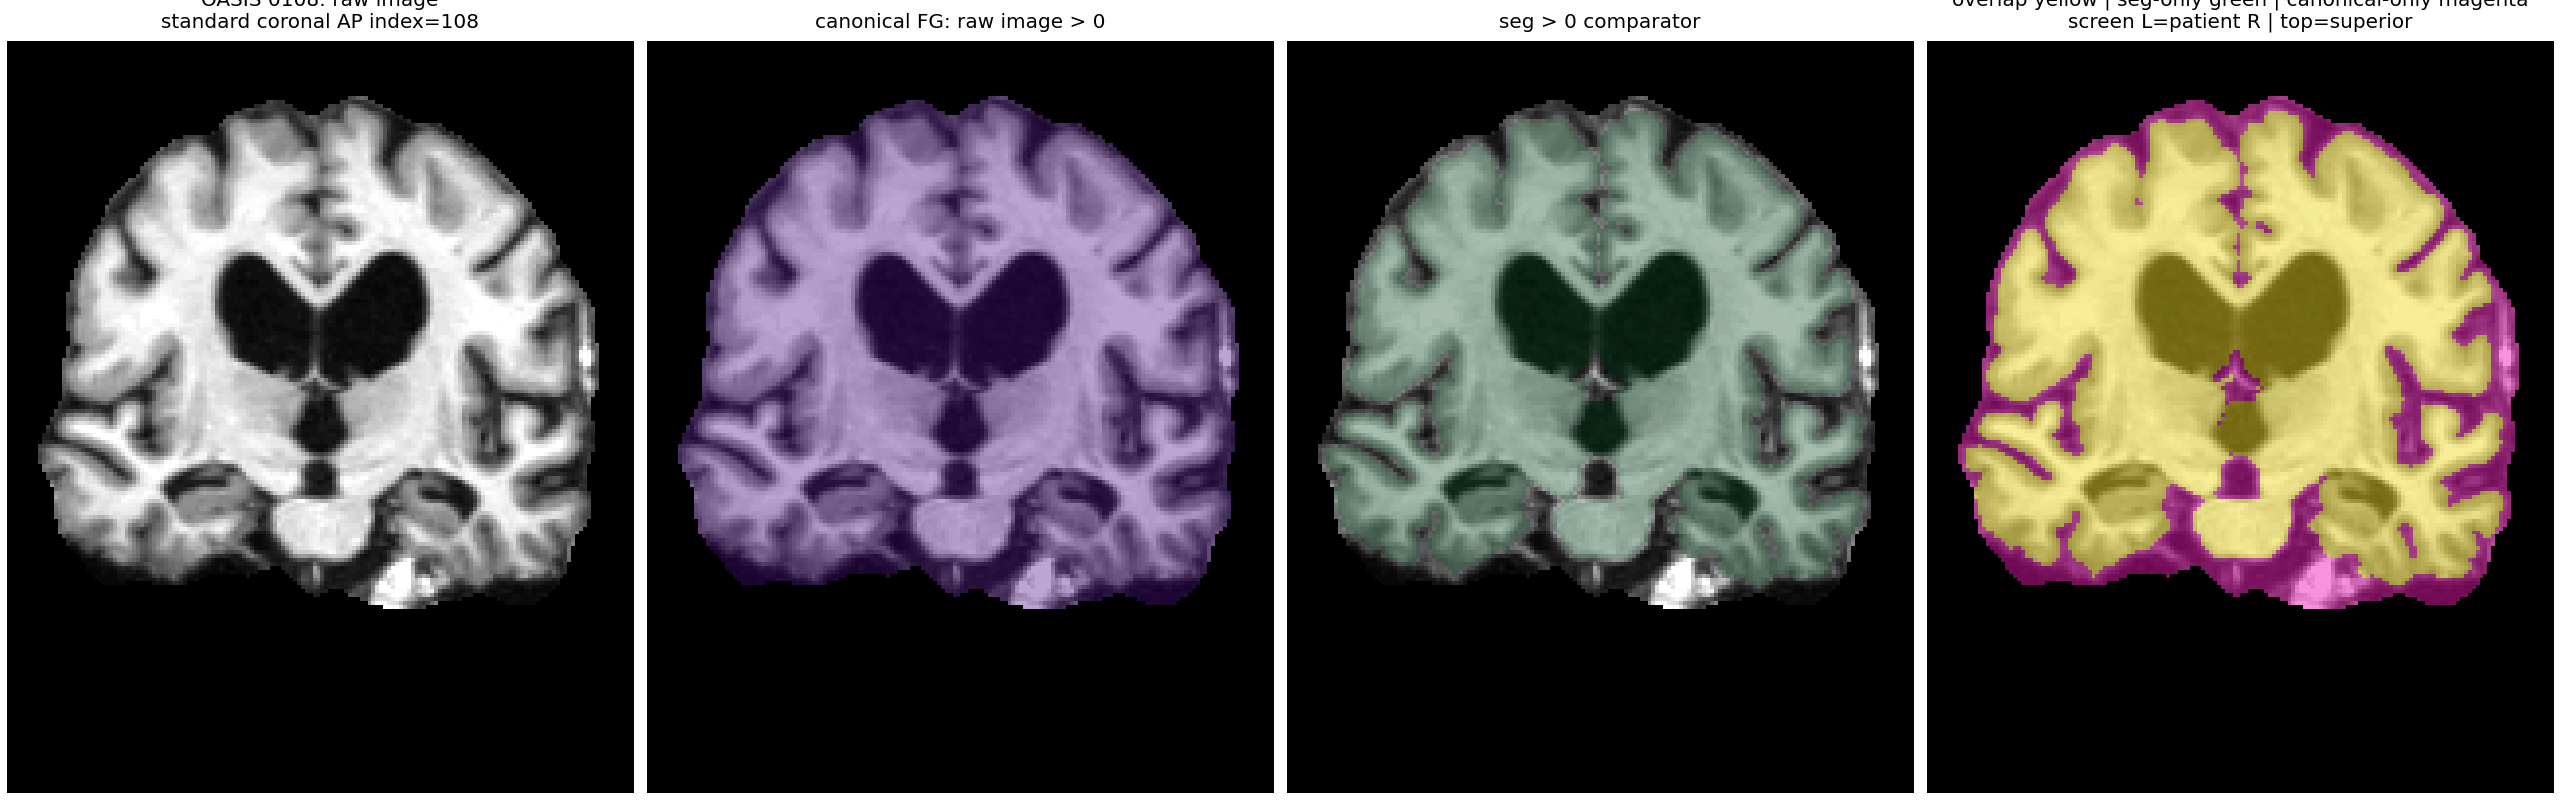

### OASIS 0113 | Dice 0.8219

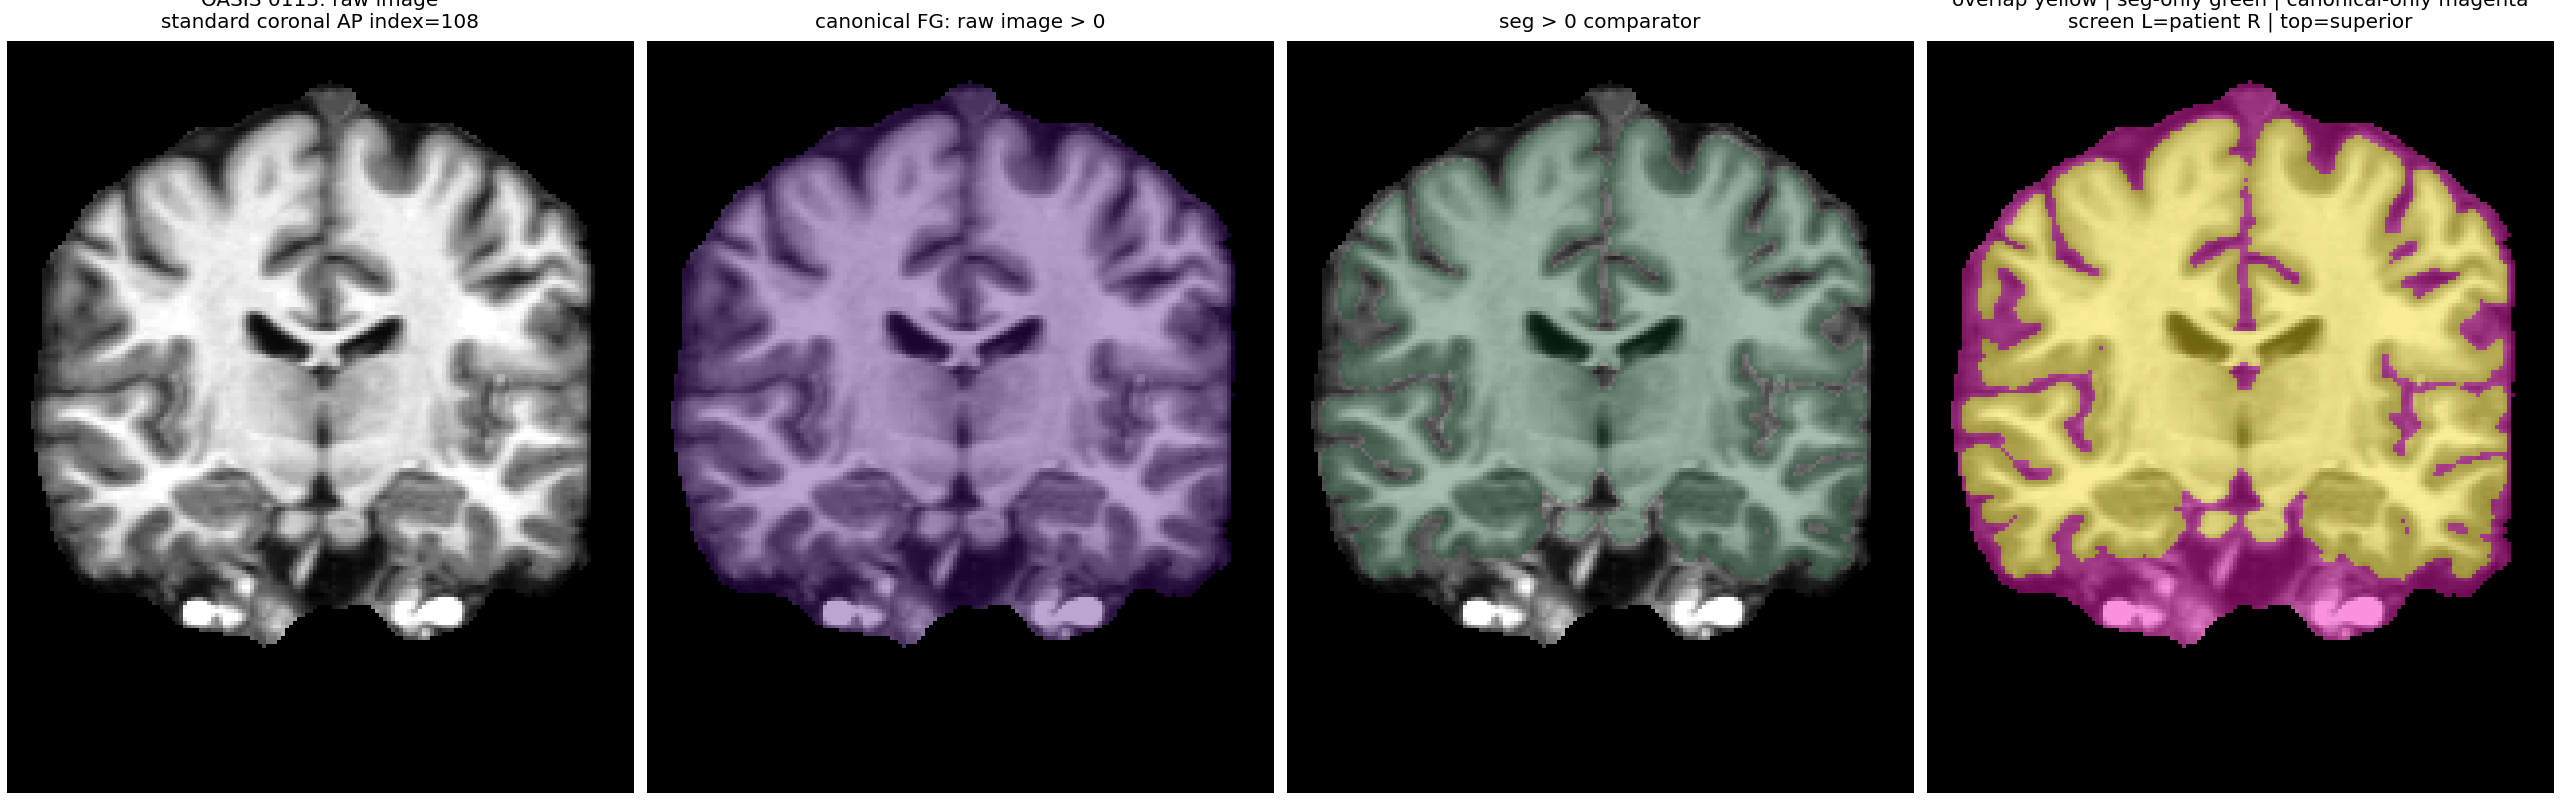

### OASIS 0115 | Dice 0.8431

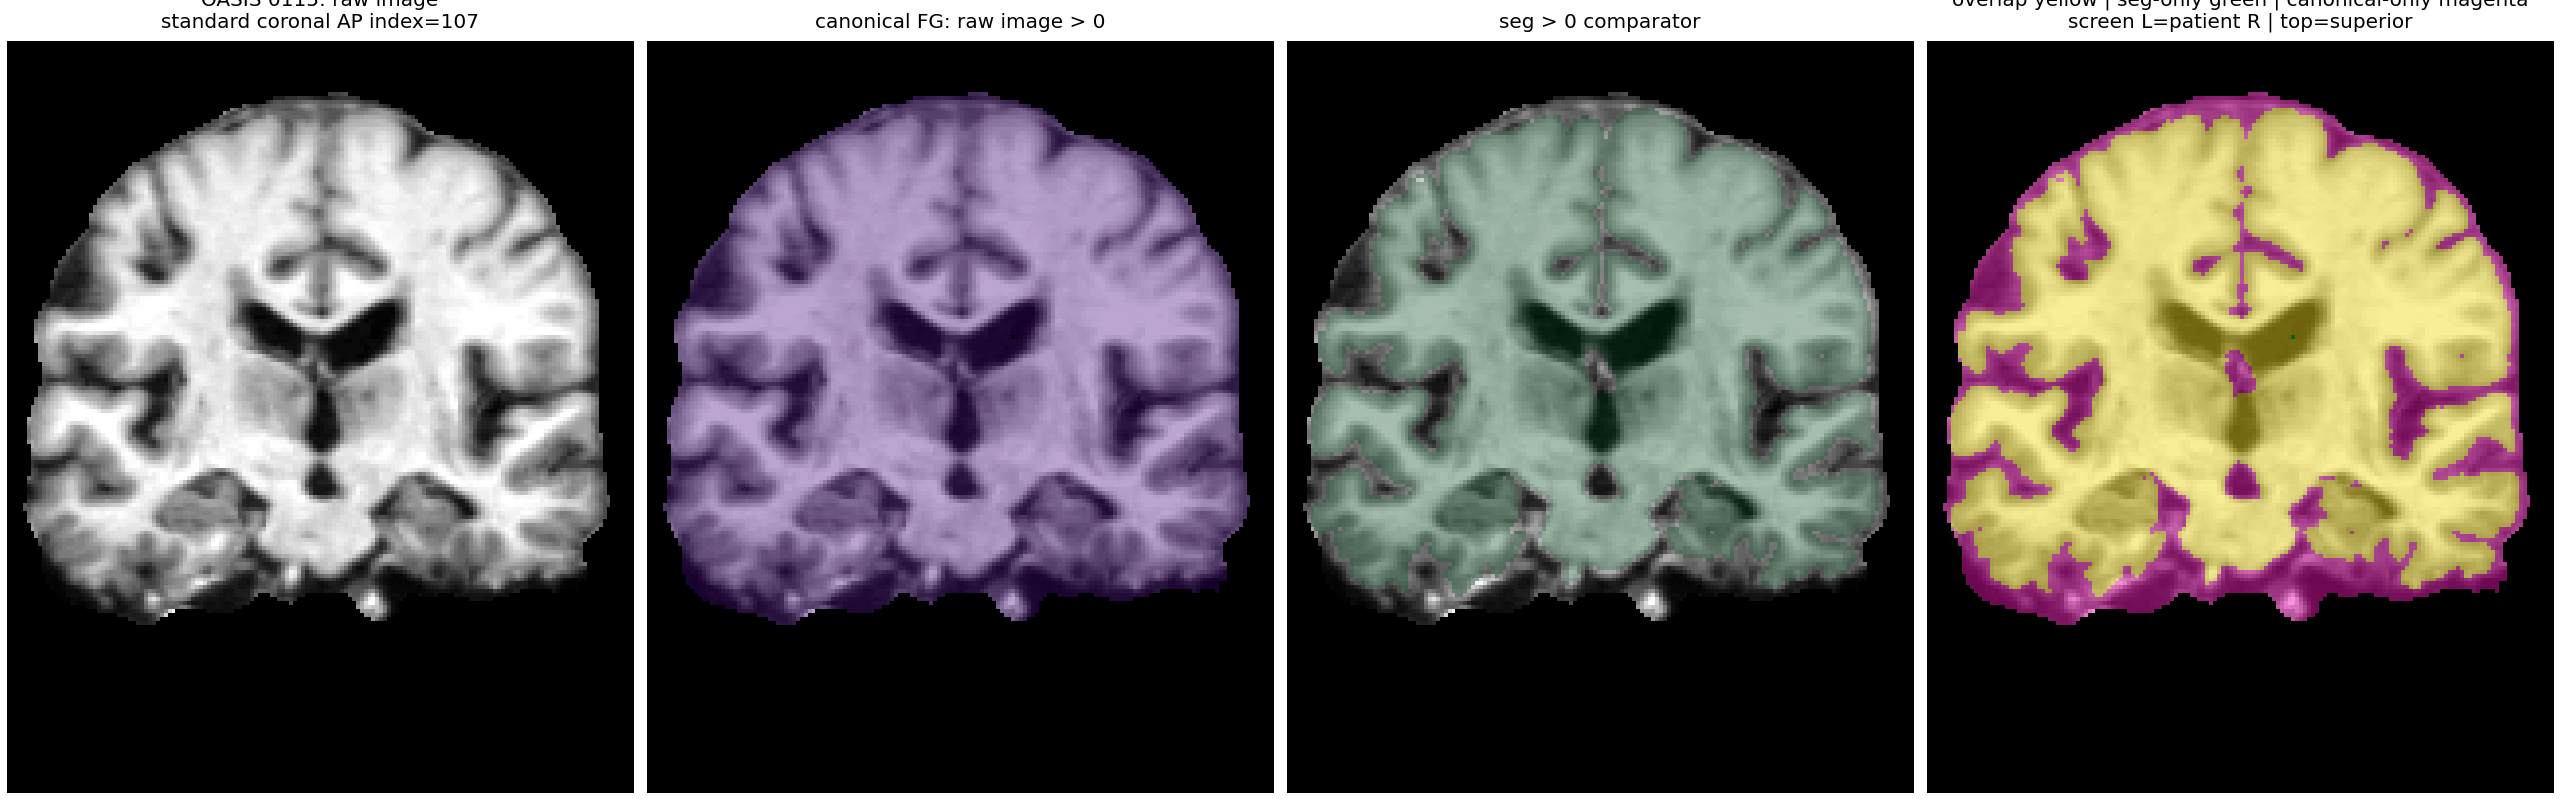

### OASIS 0117 | Dice 0.8188

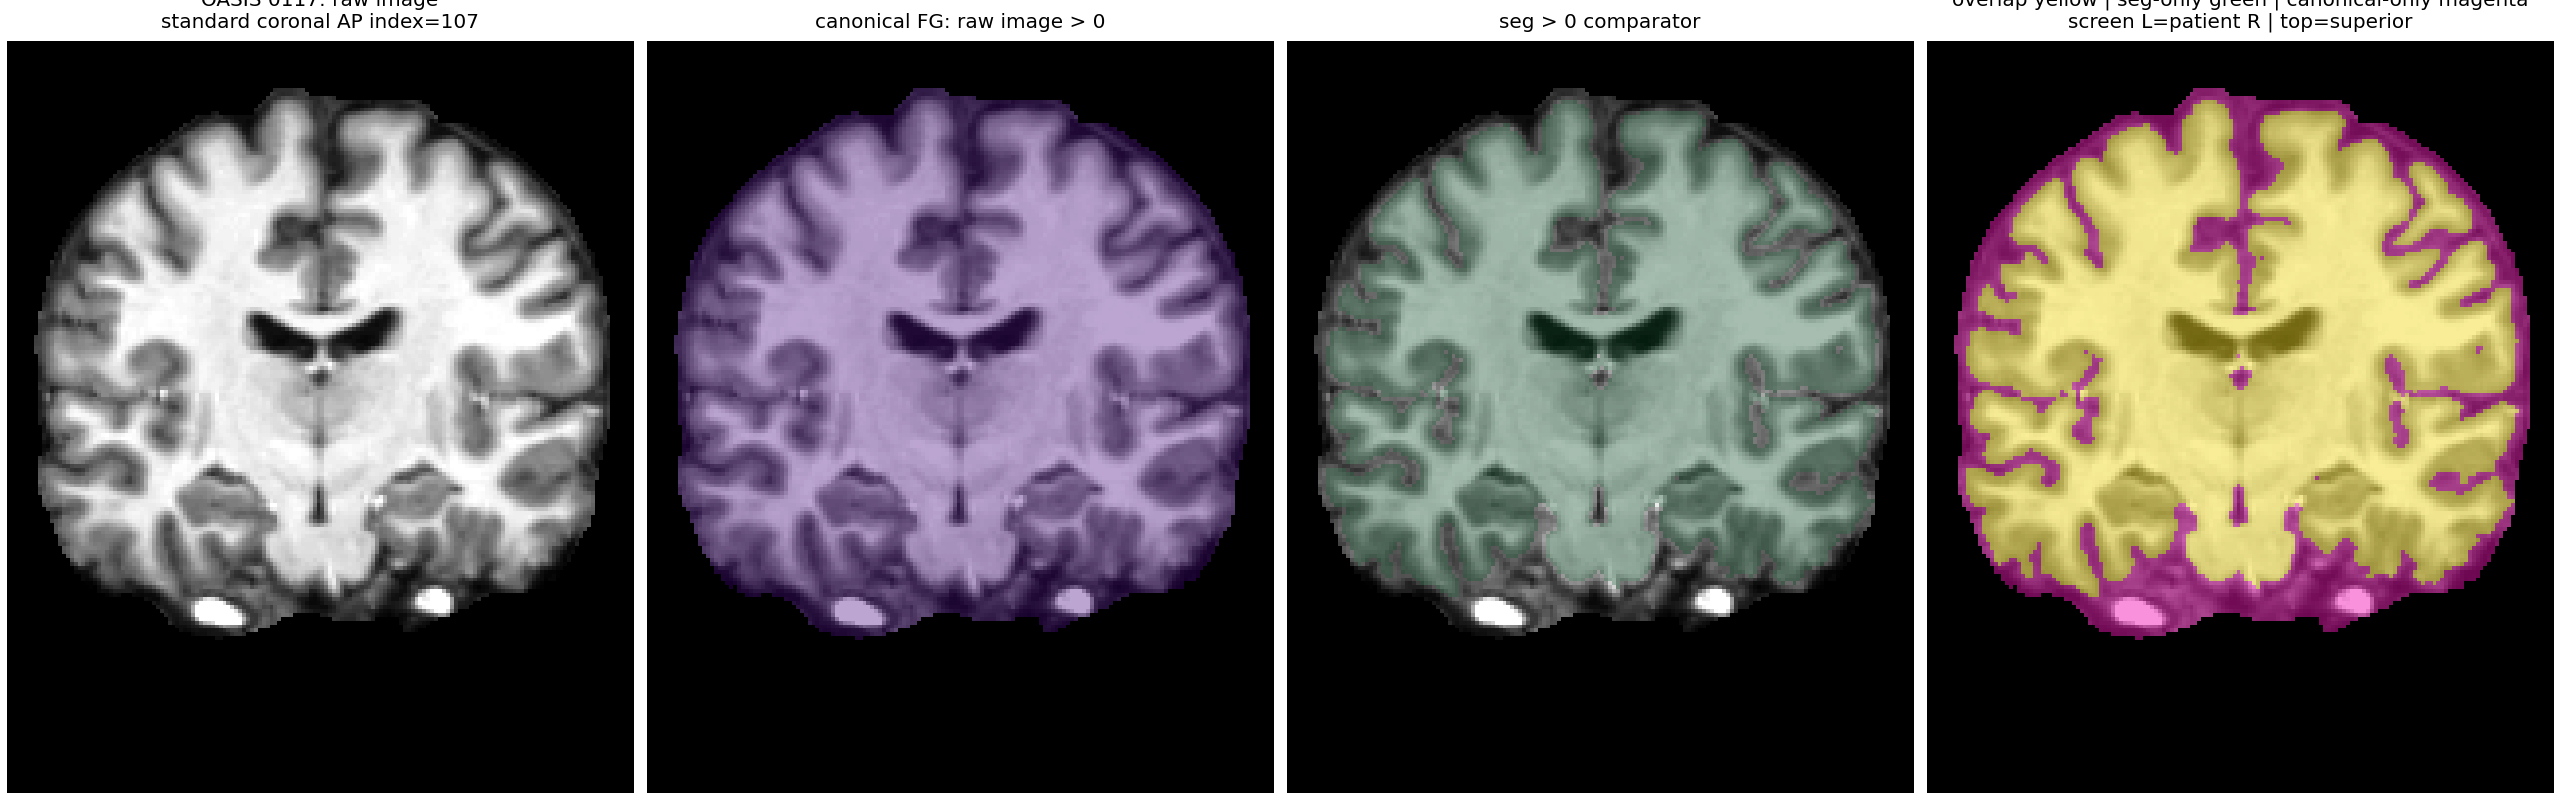

### OASIS 0136 | Dice 0.8287

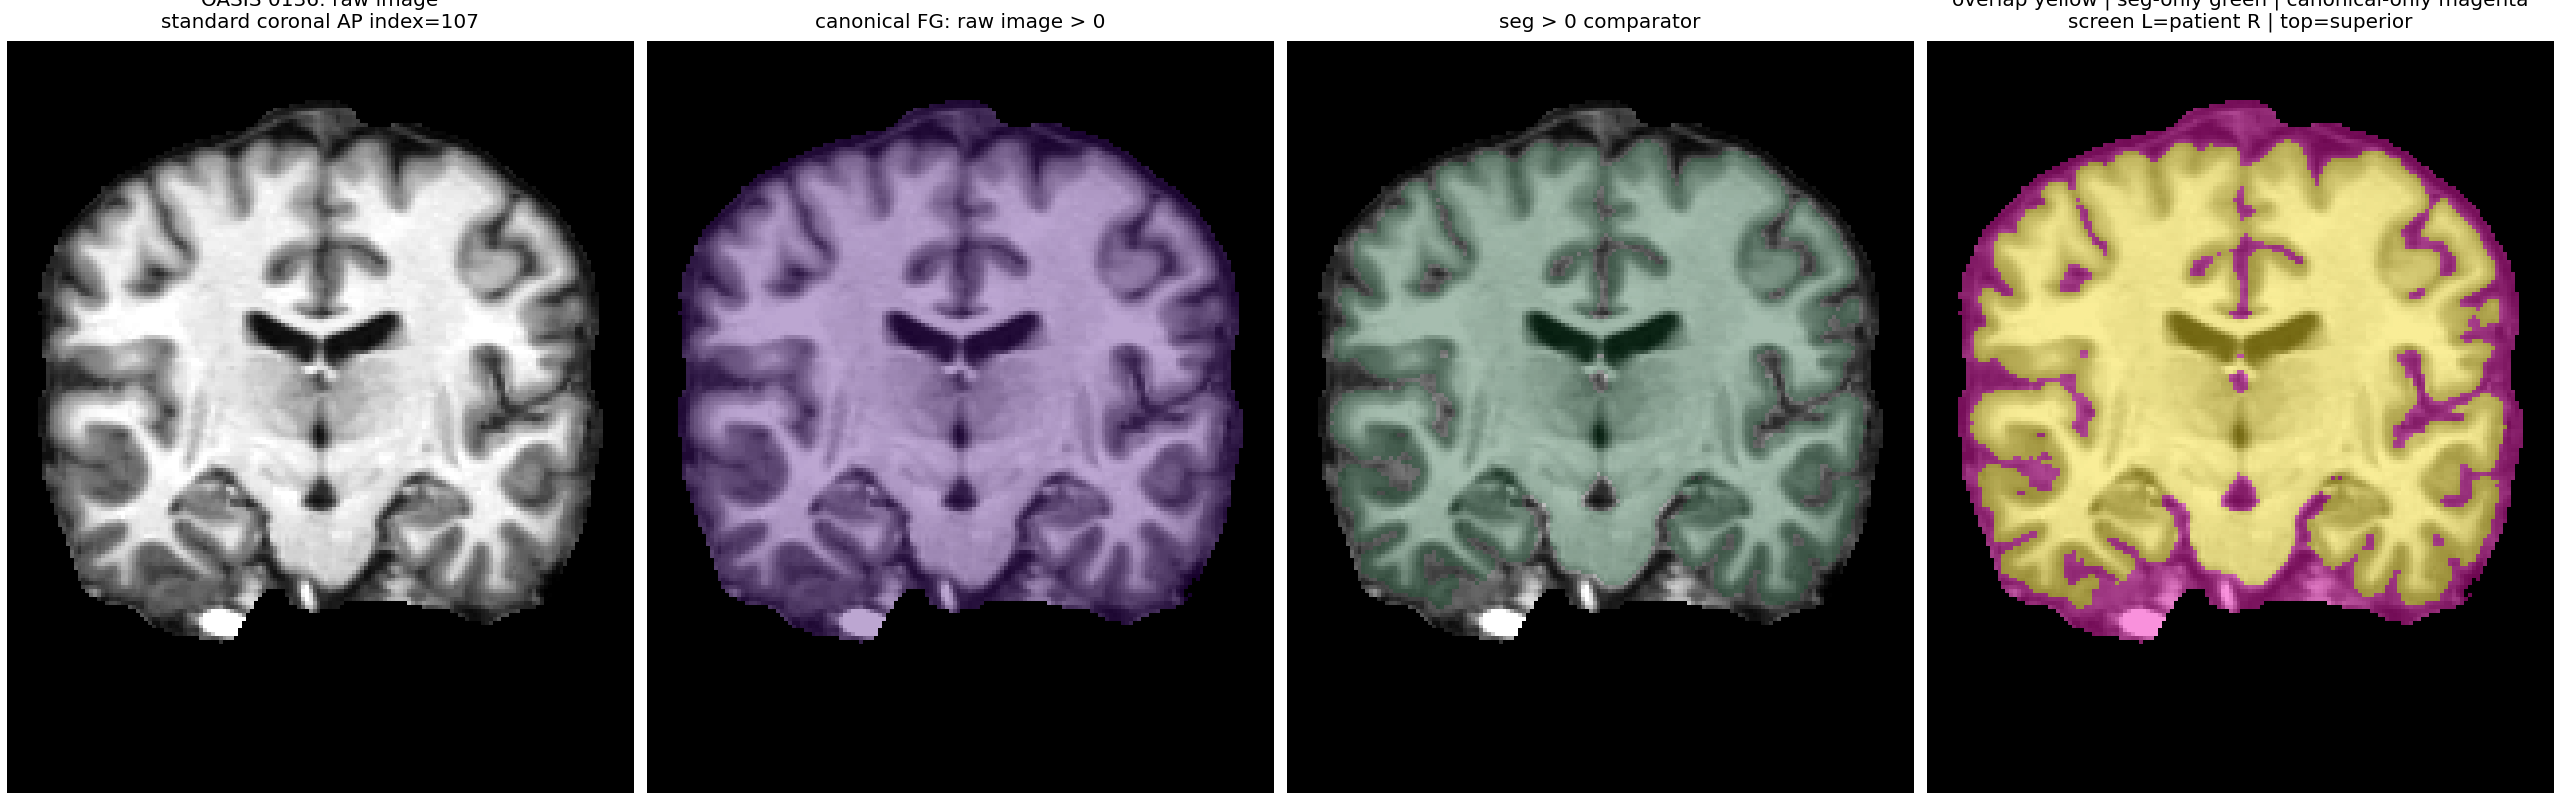

### OASIS 0149 | Dice 0.8193

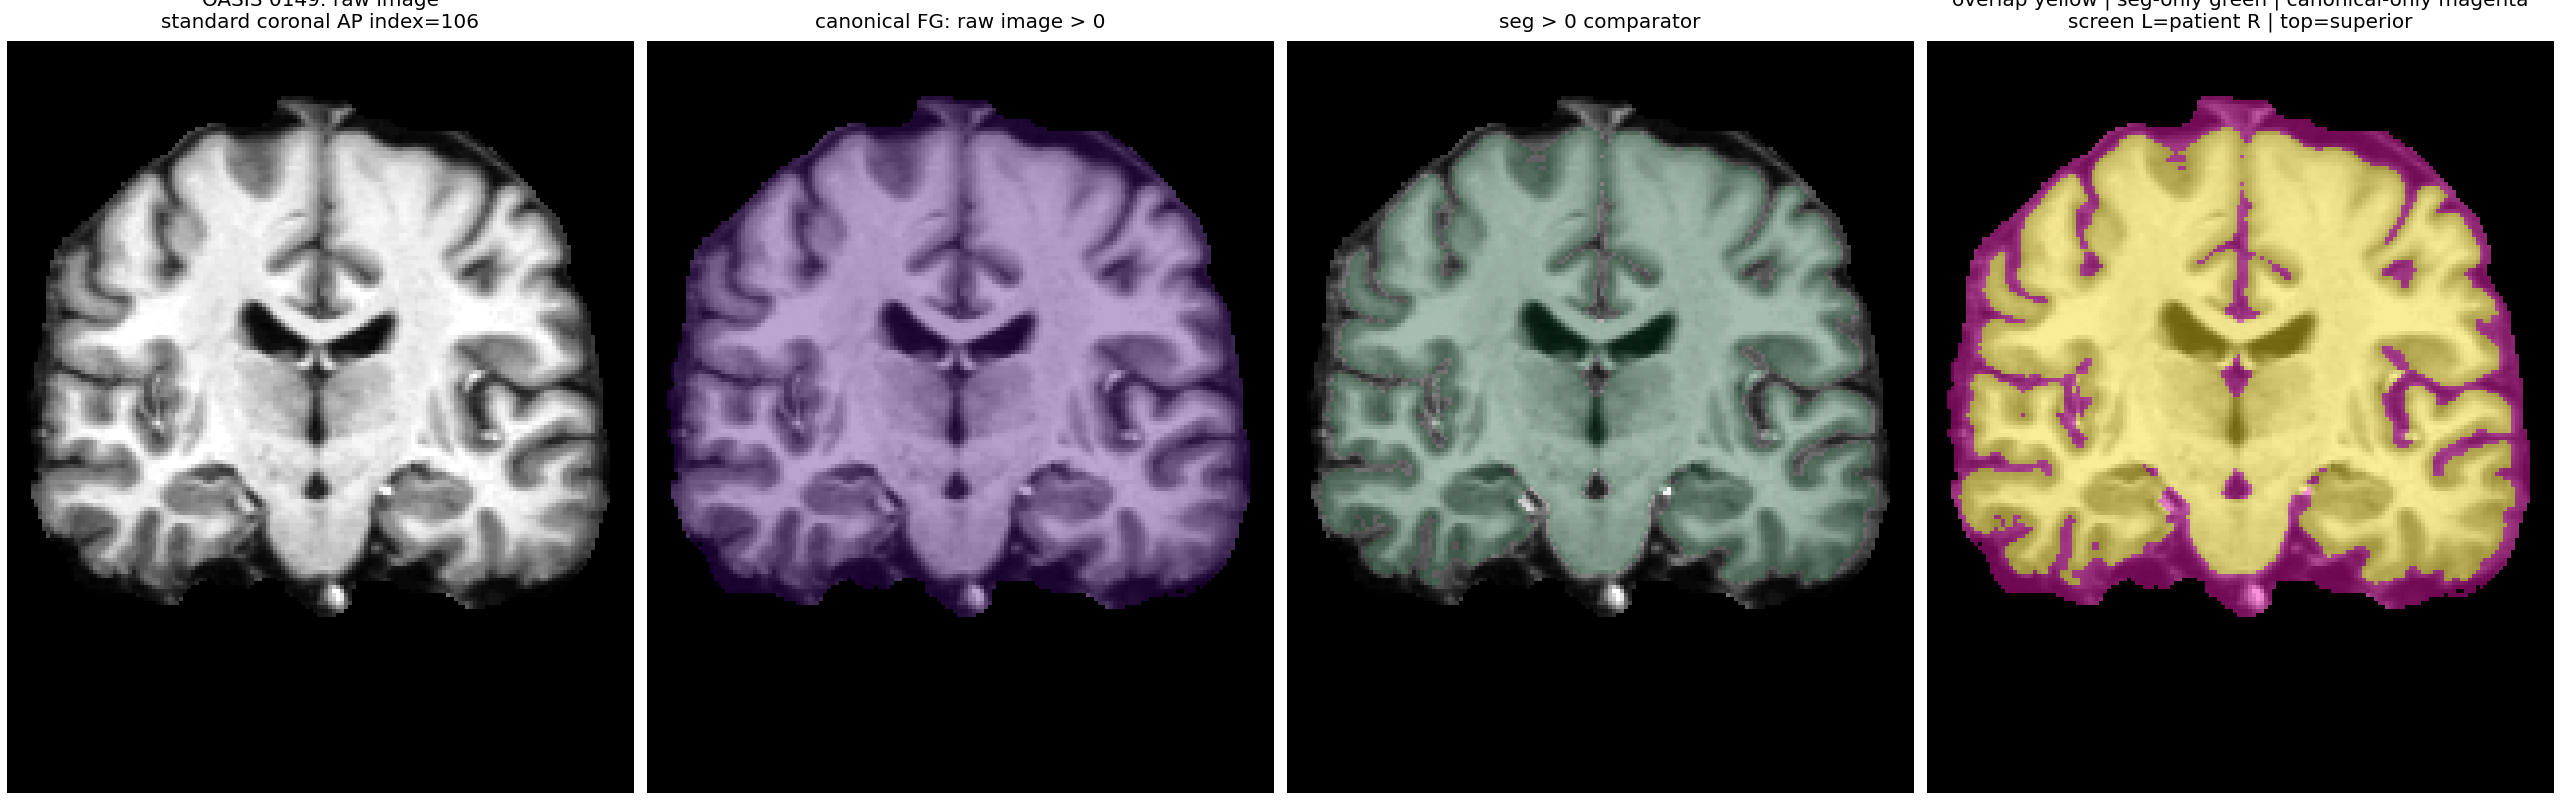

### OASIS 0173 | Dice 0.8259

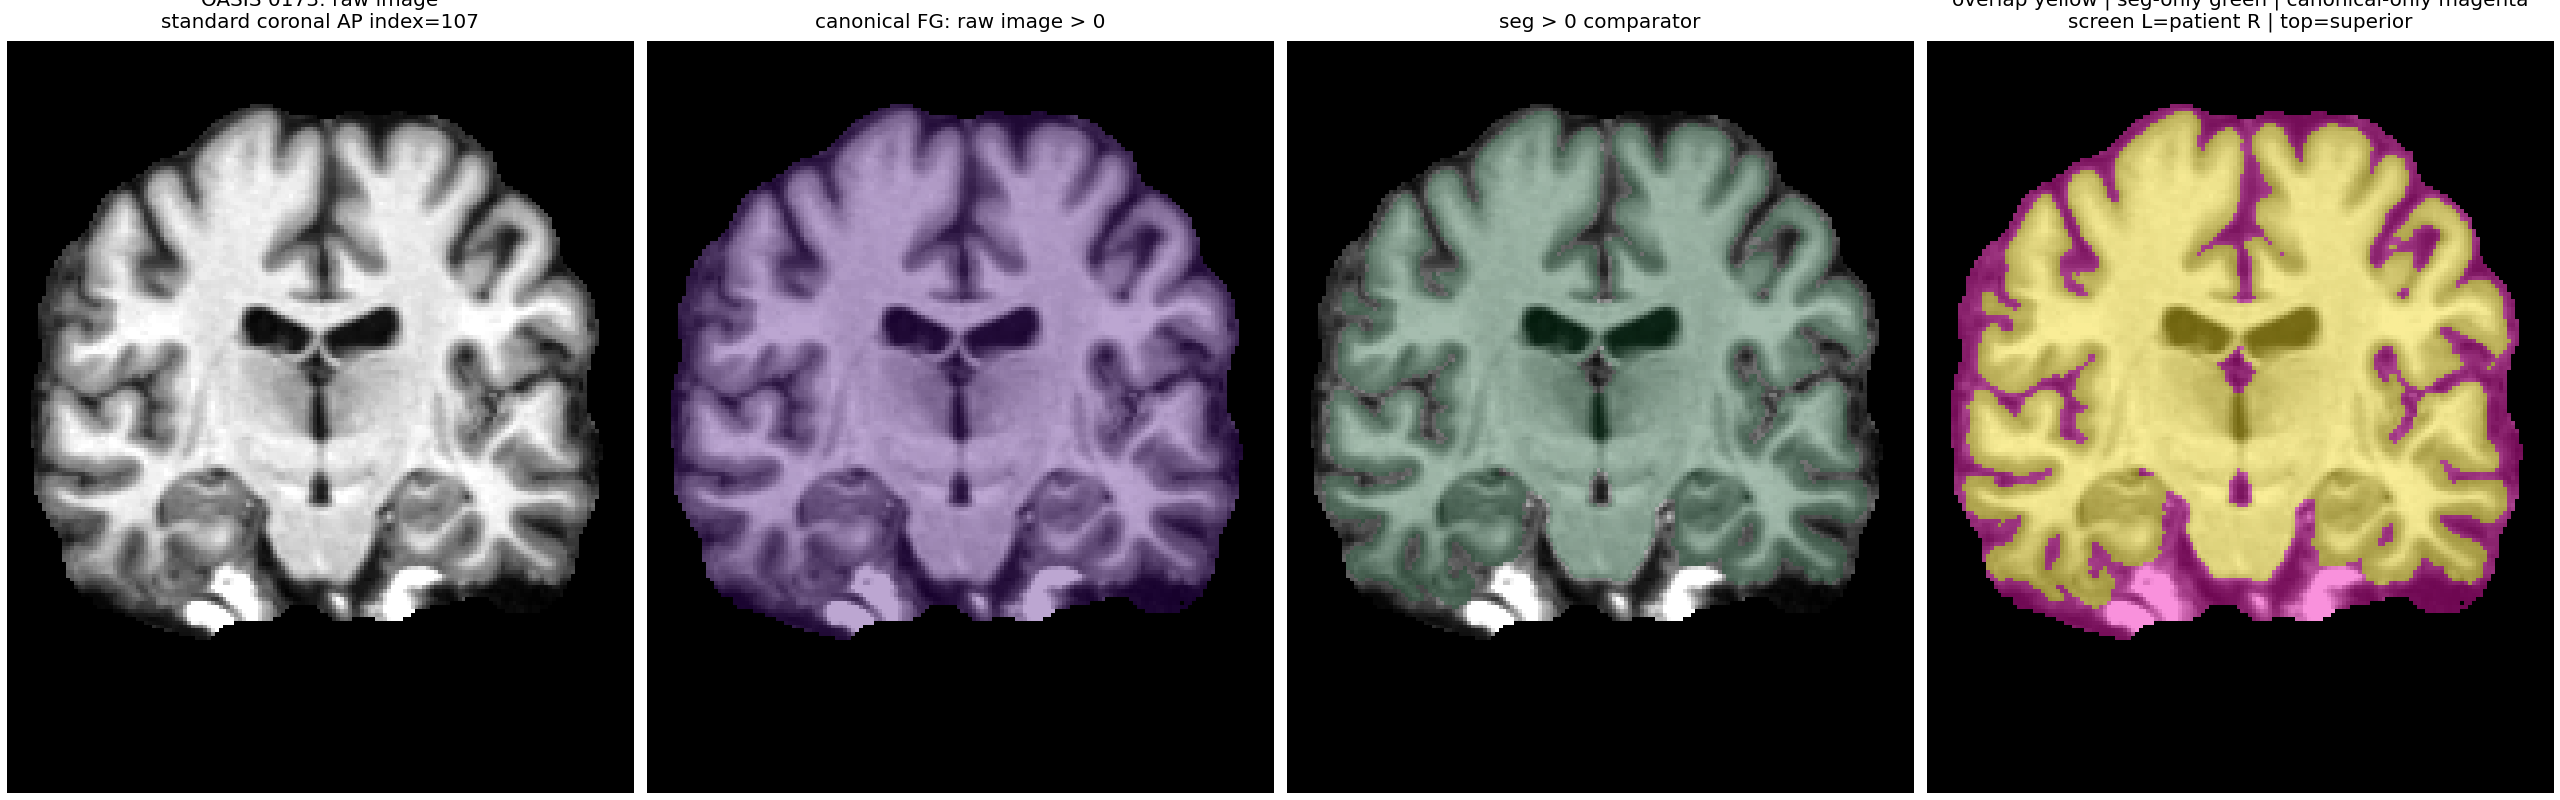

### OASIS 0184 | Dice 0.8318

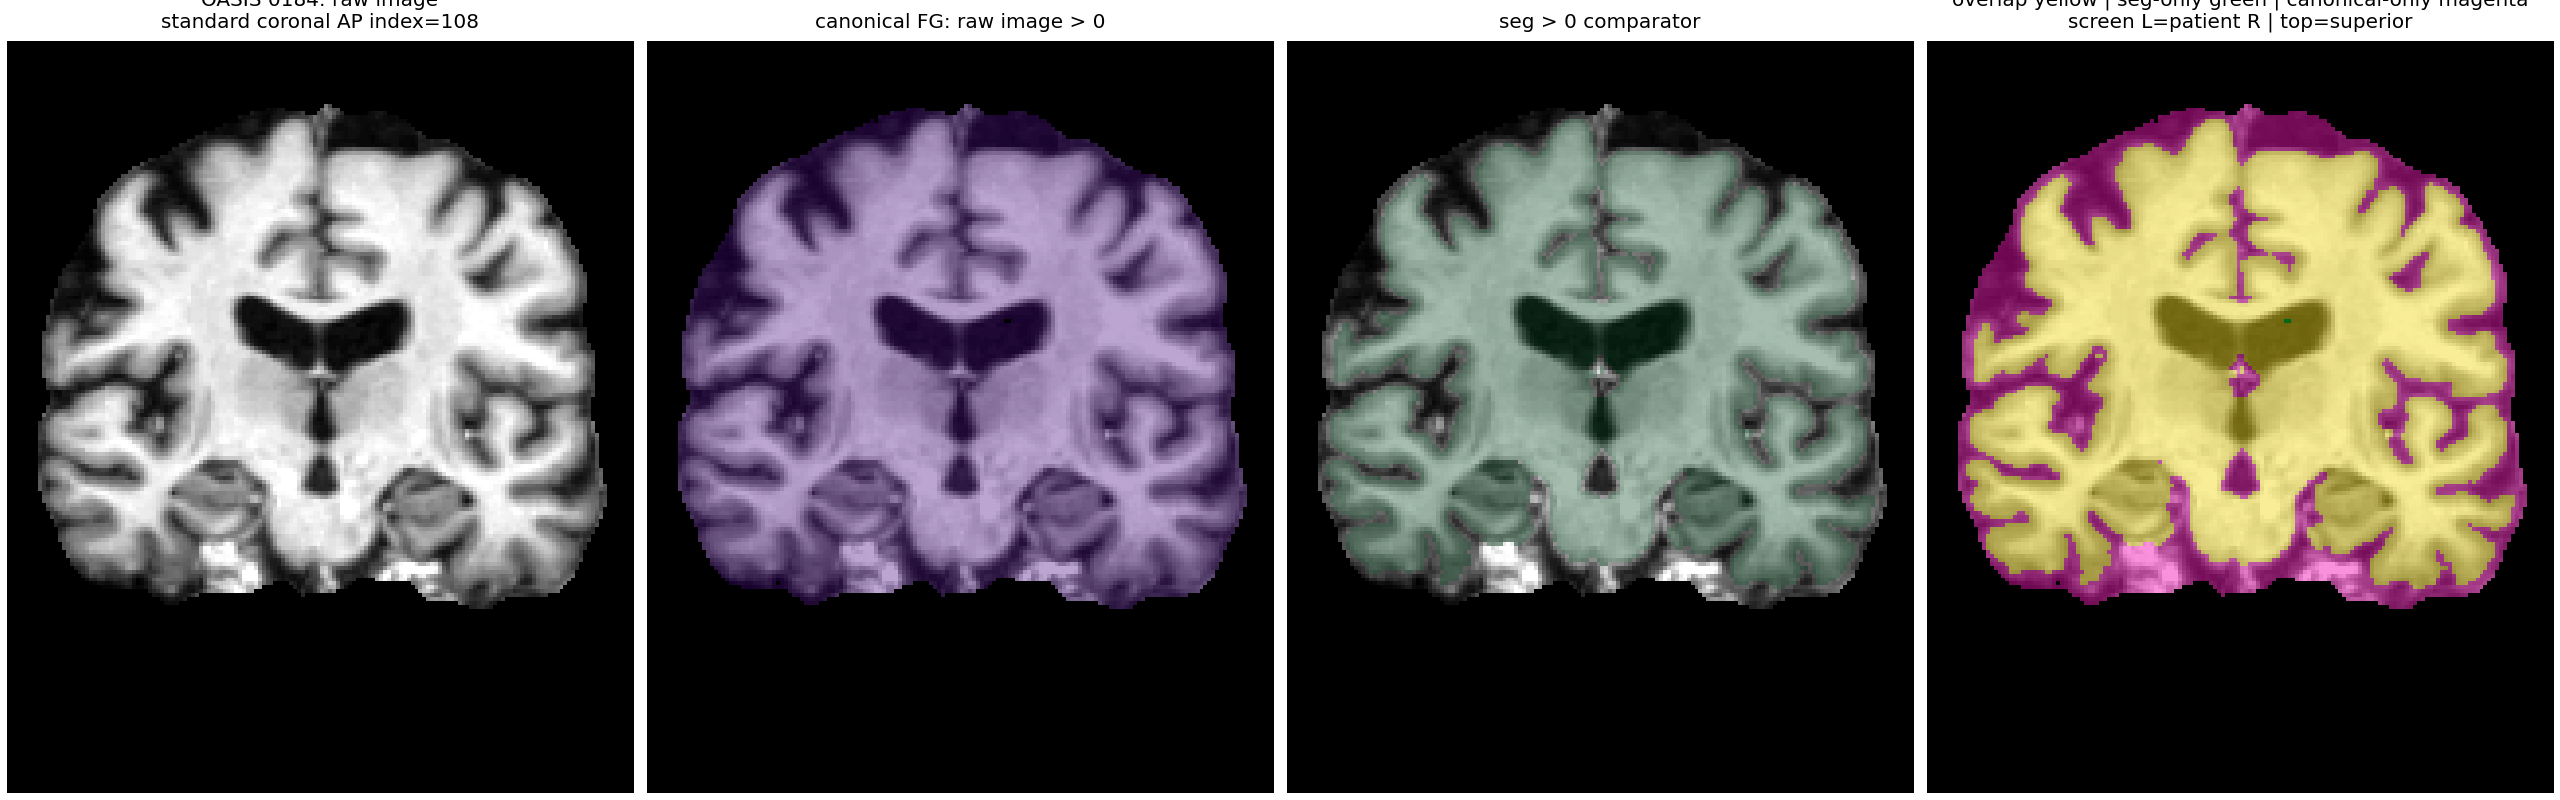

### OASIS 0194 | Dice 0.8265

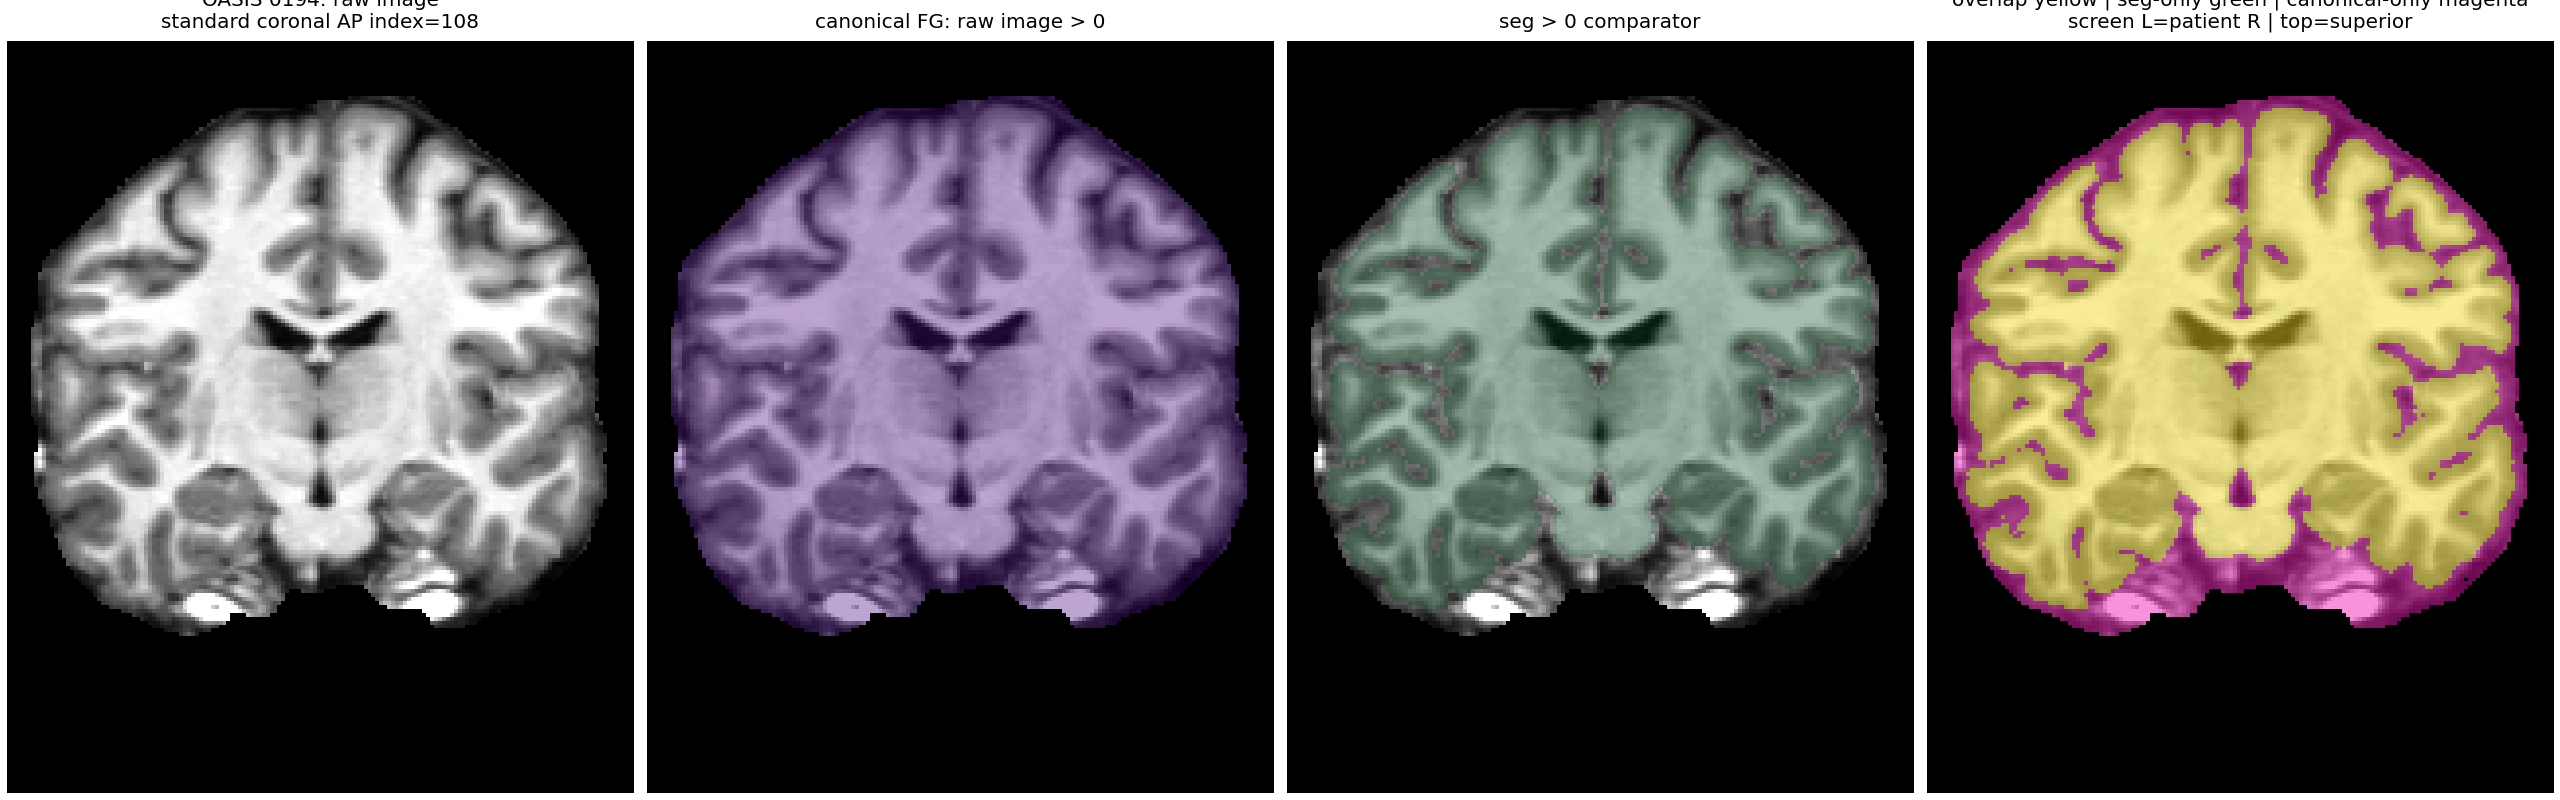

### OASIS 0215 | Dice 0.8352

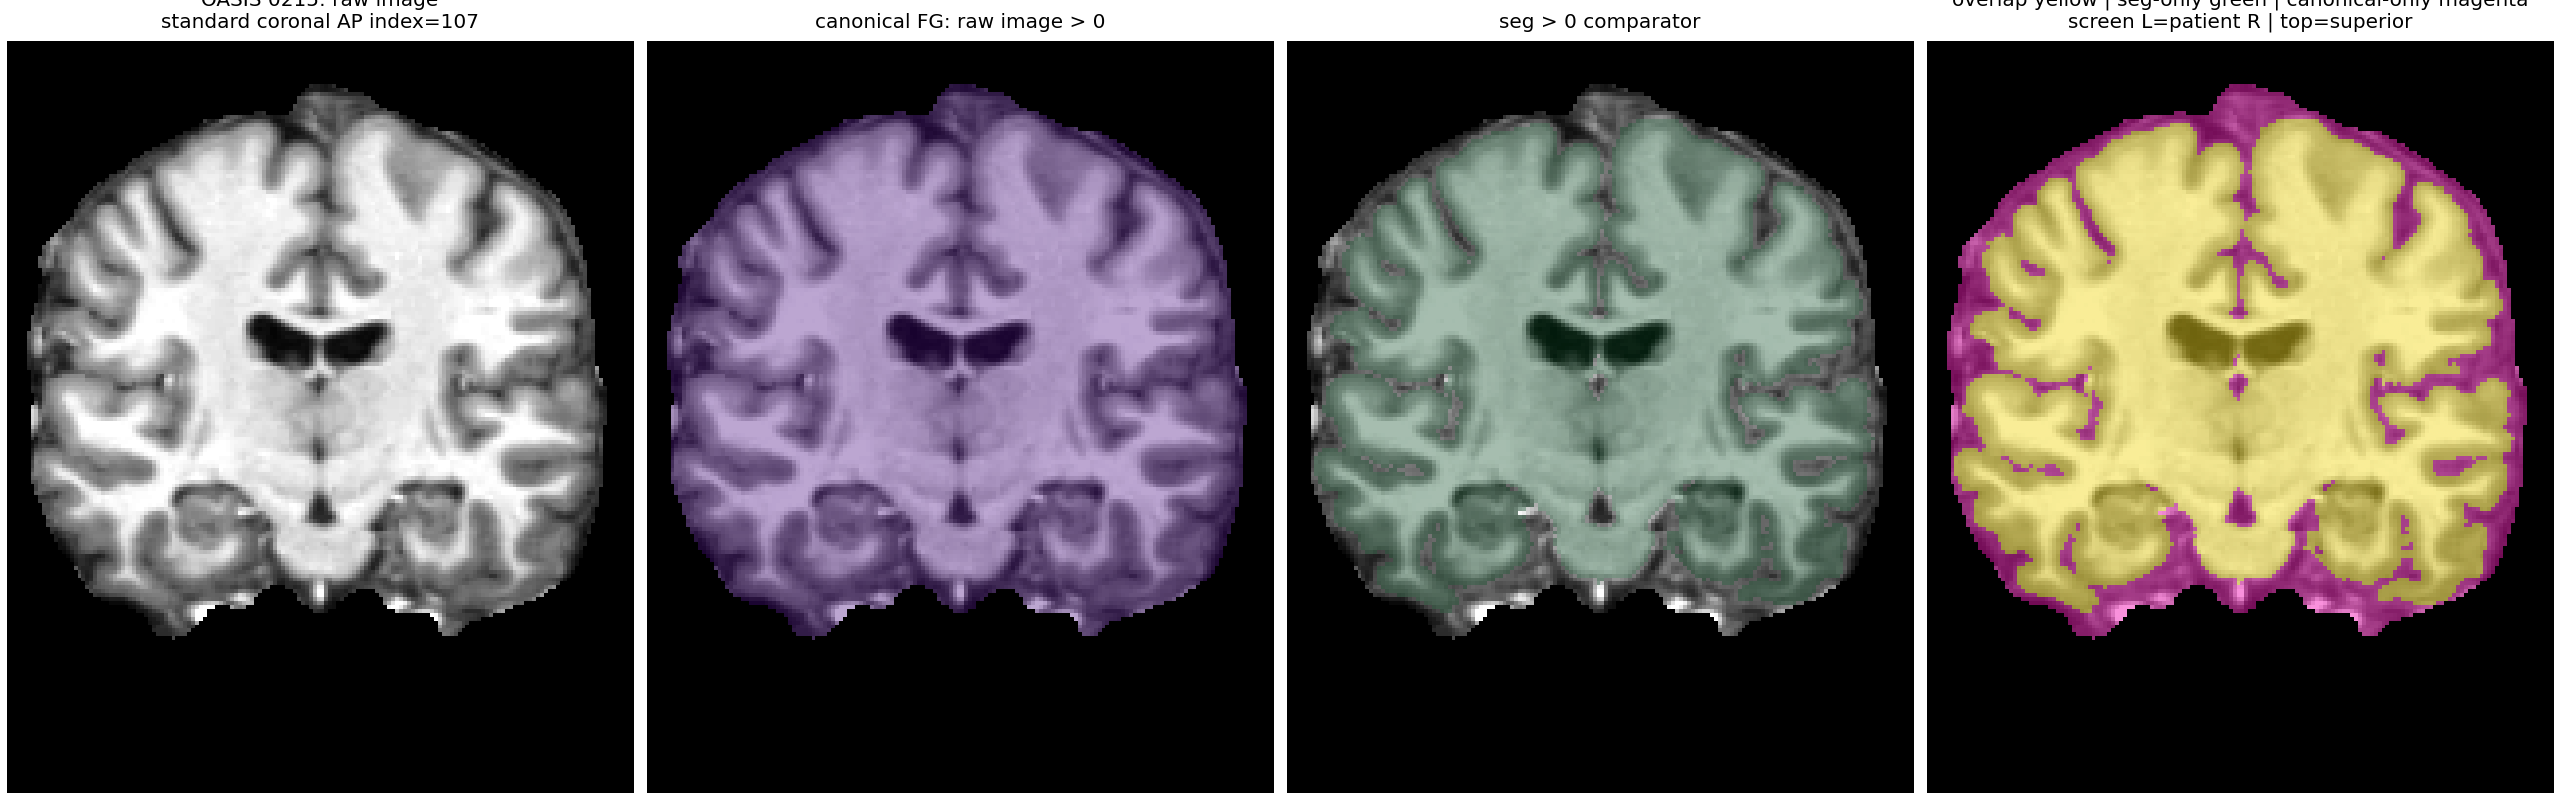

### OASIS 0288 | Dice 0.8366

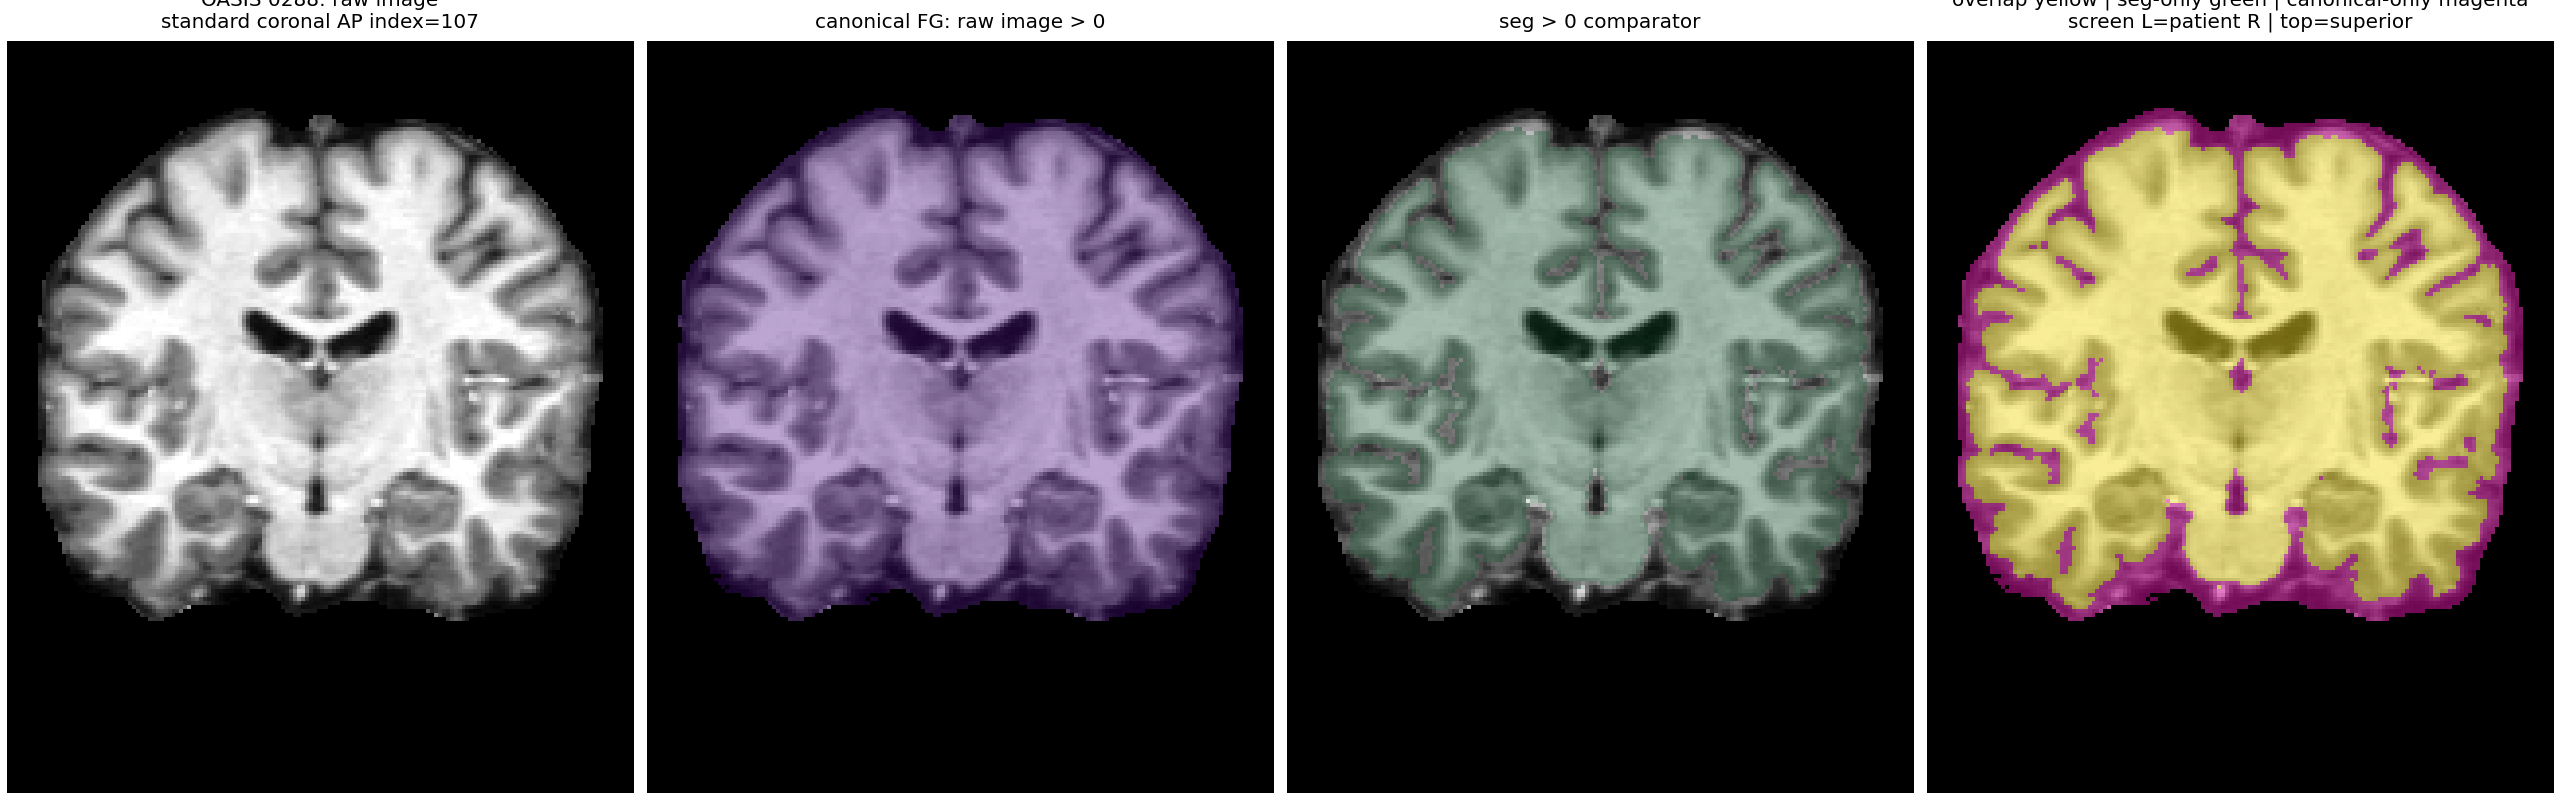

### OASIS 0322 | Dice 0.8334

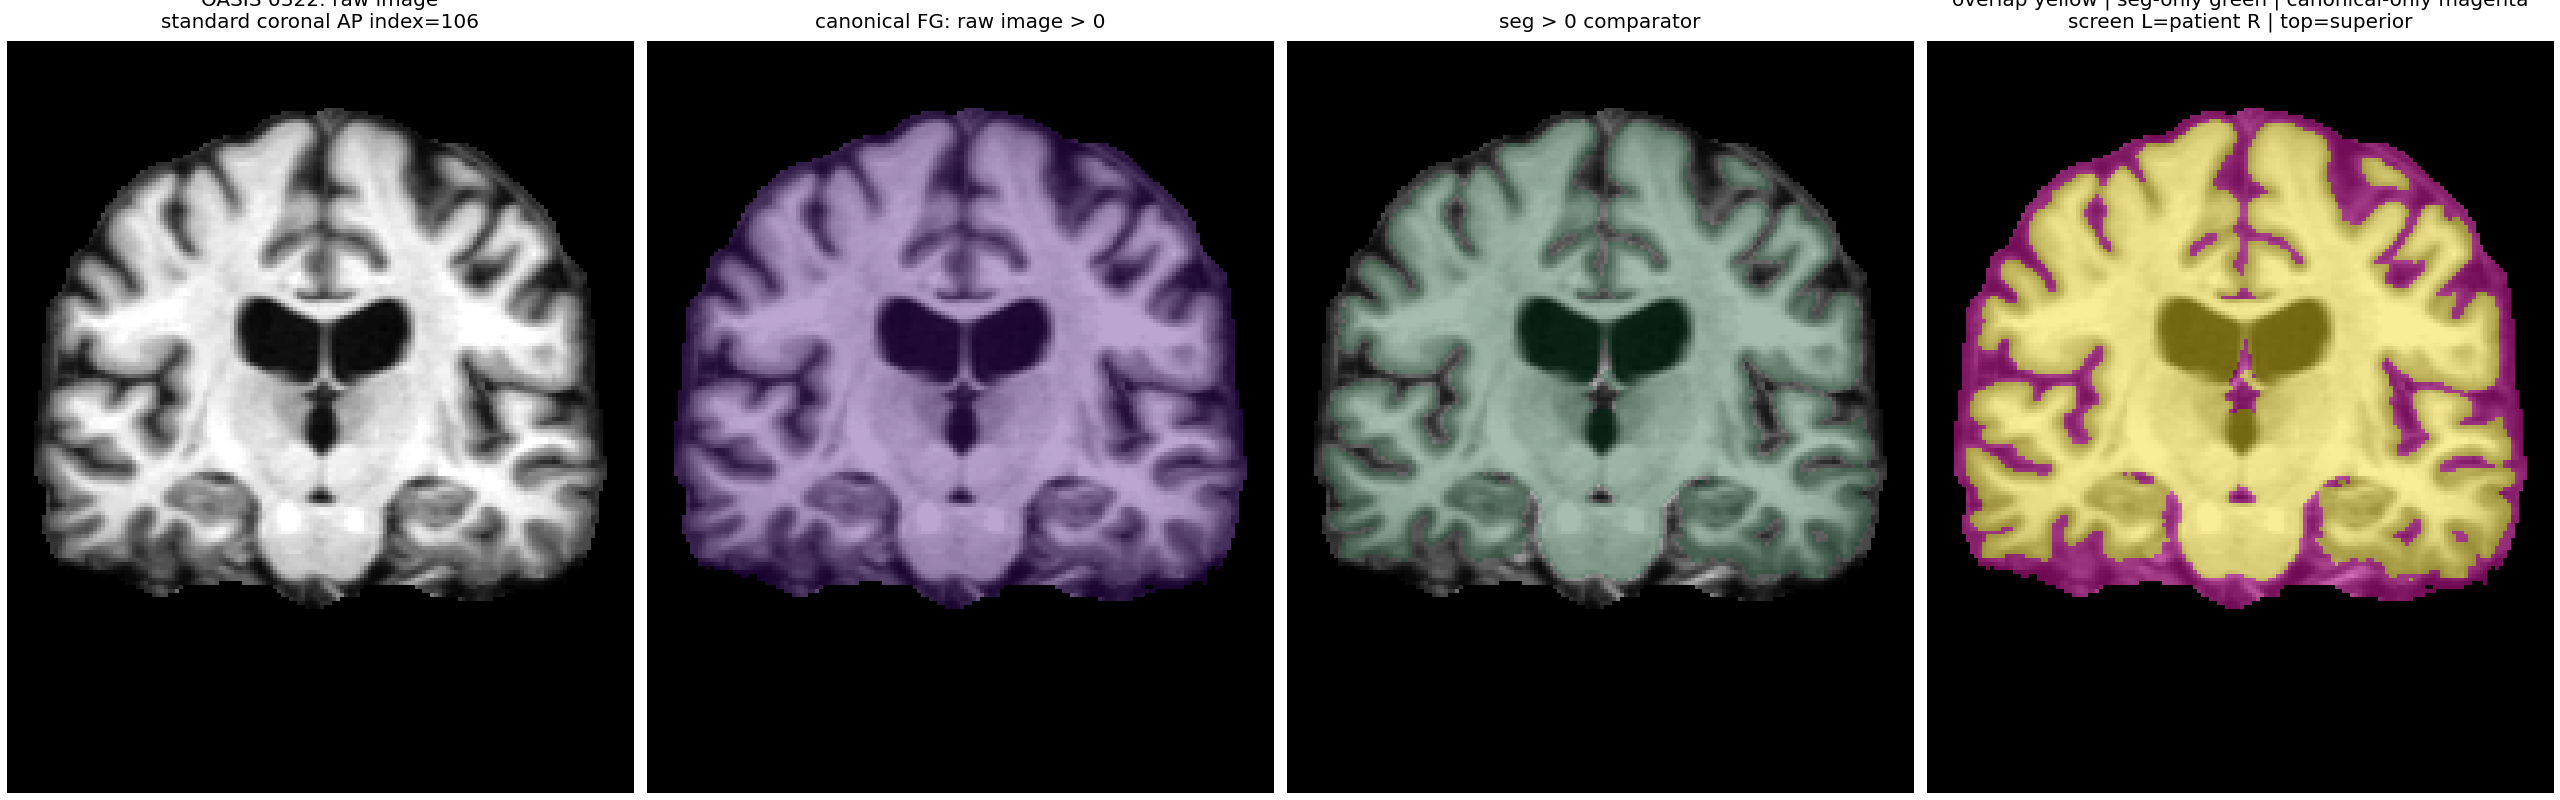

### OASIS 0326 | Dice 0.8420

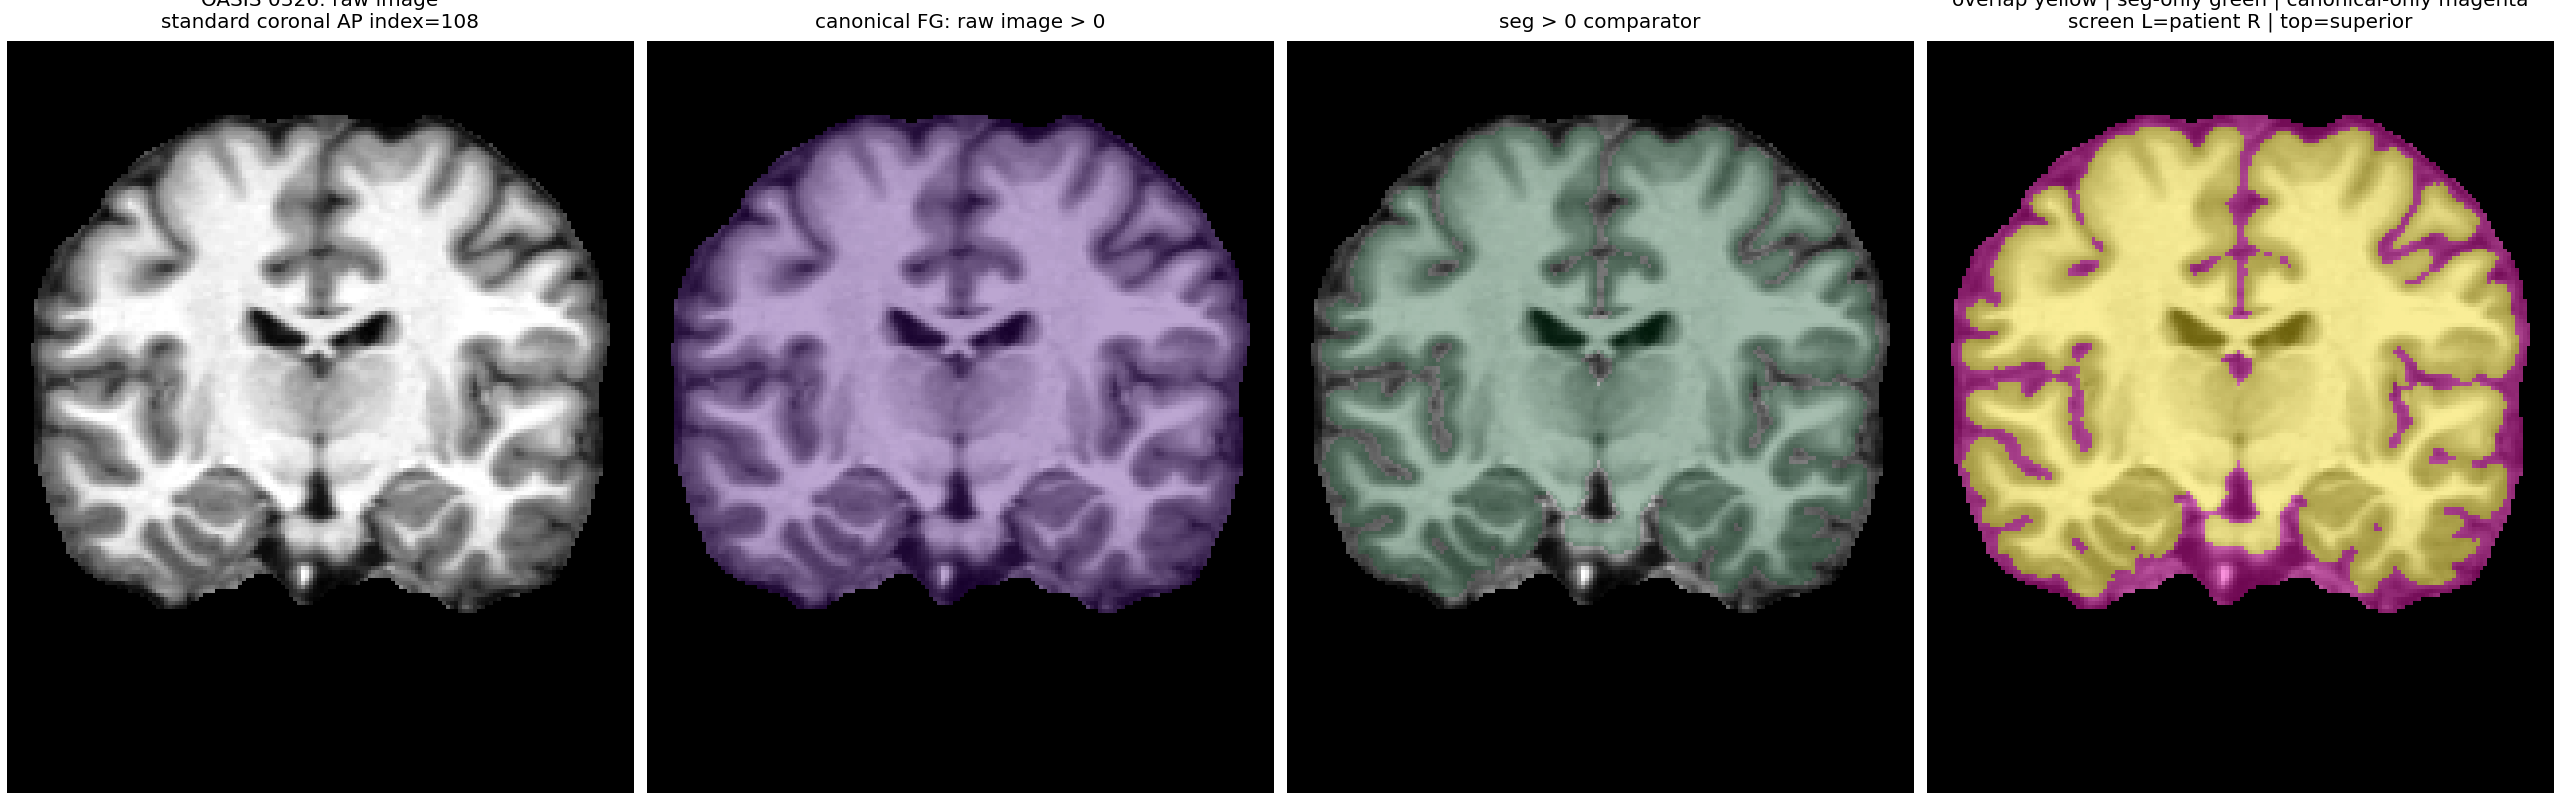

### OASIS 0333 | Dice 0.8216

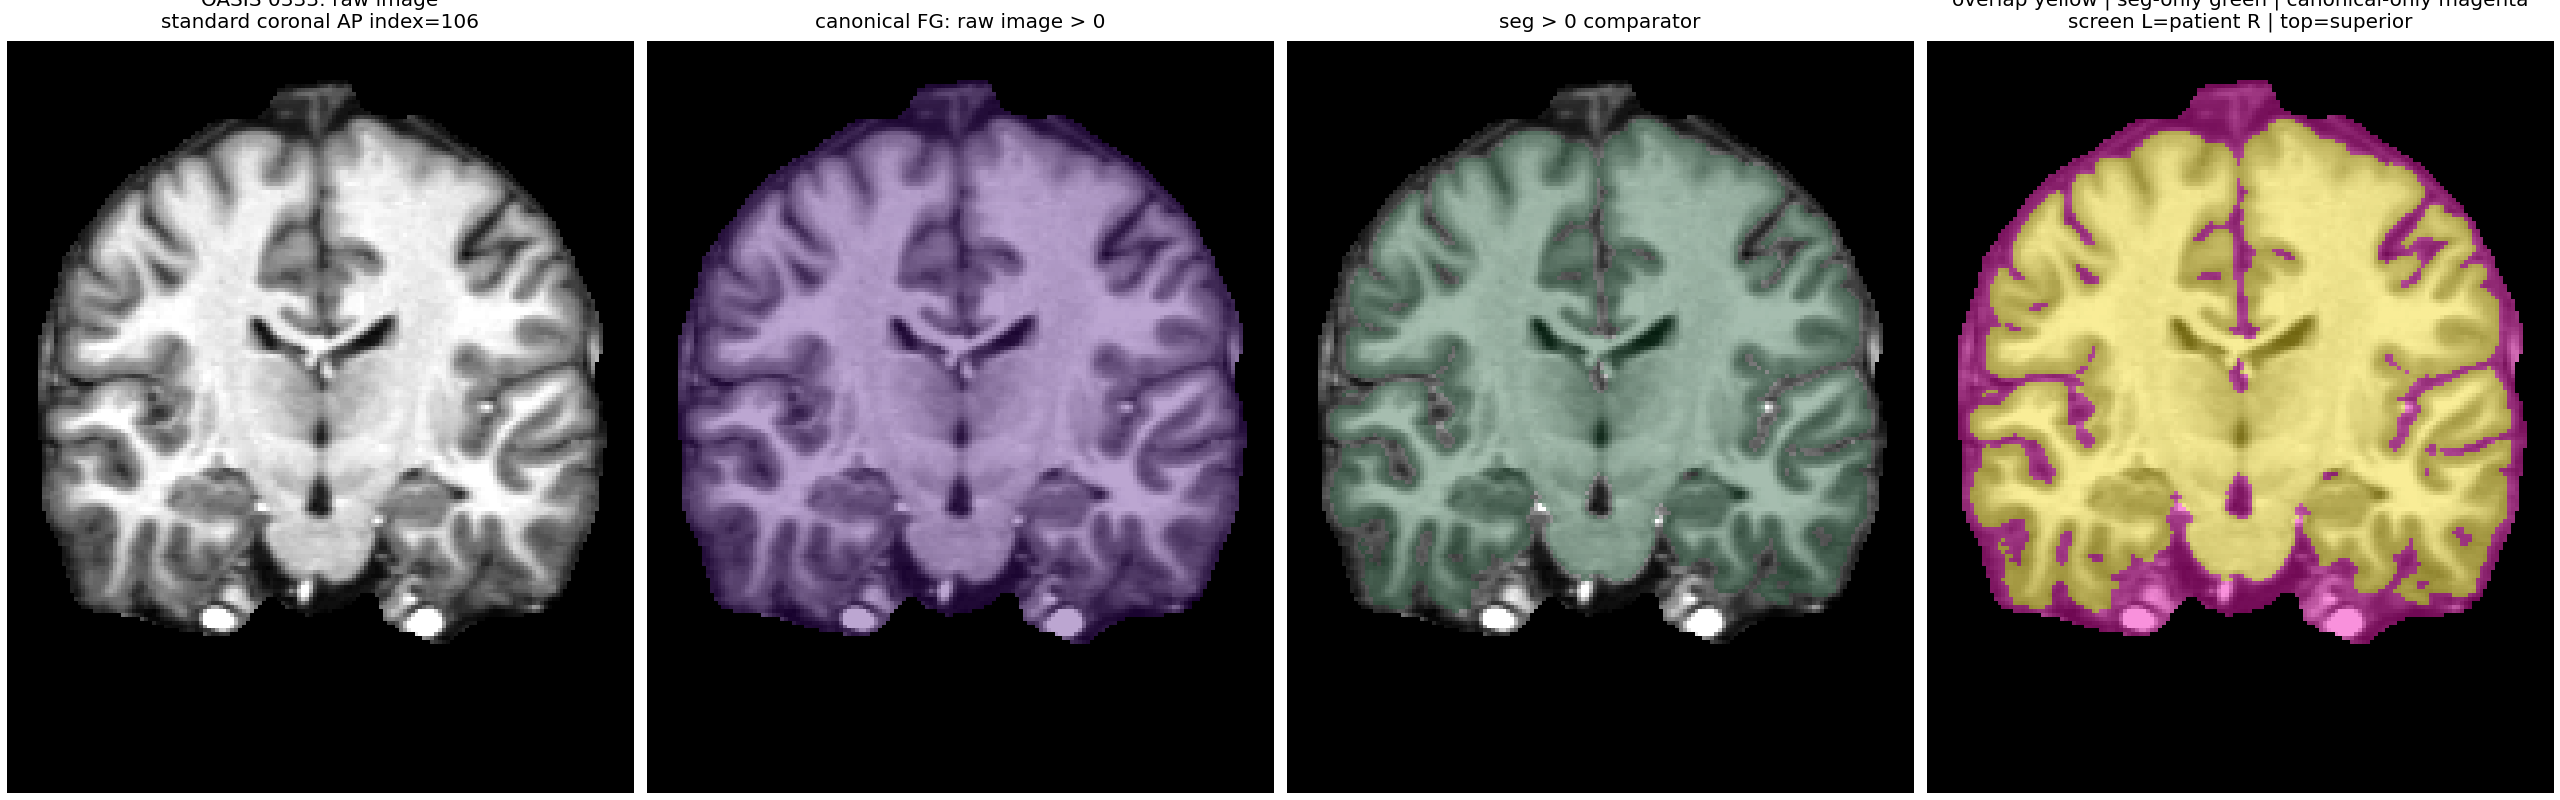

### OASIS 0394 | Dice 0.8487

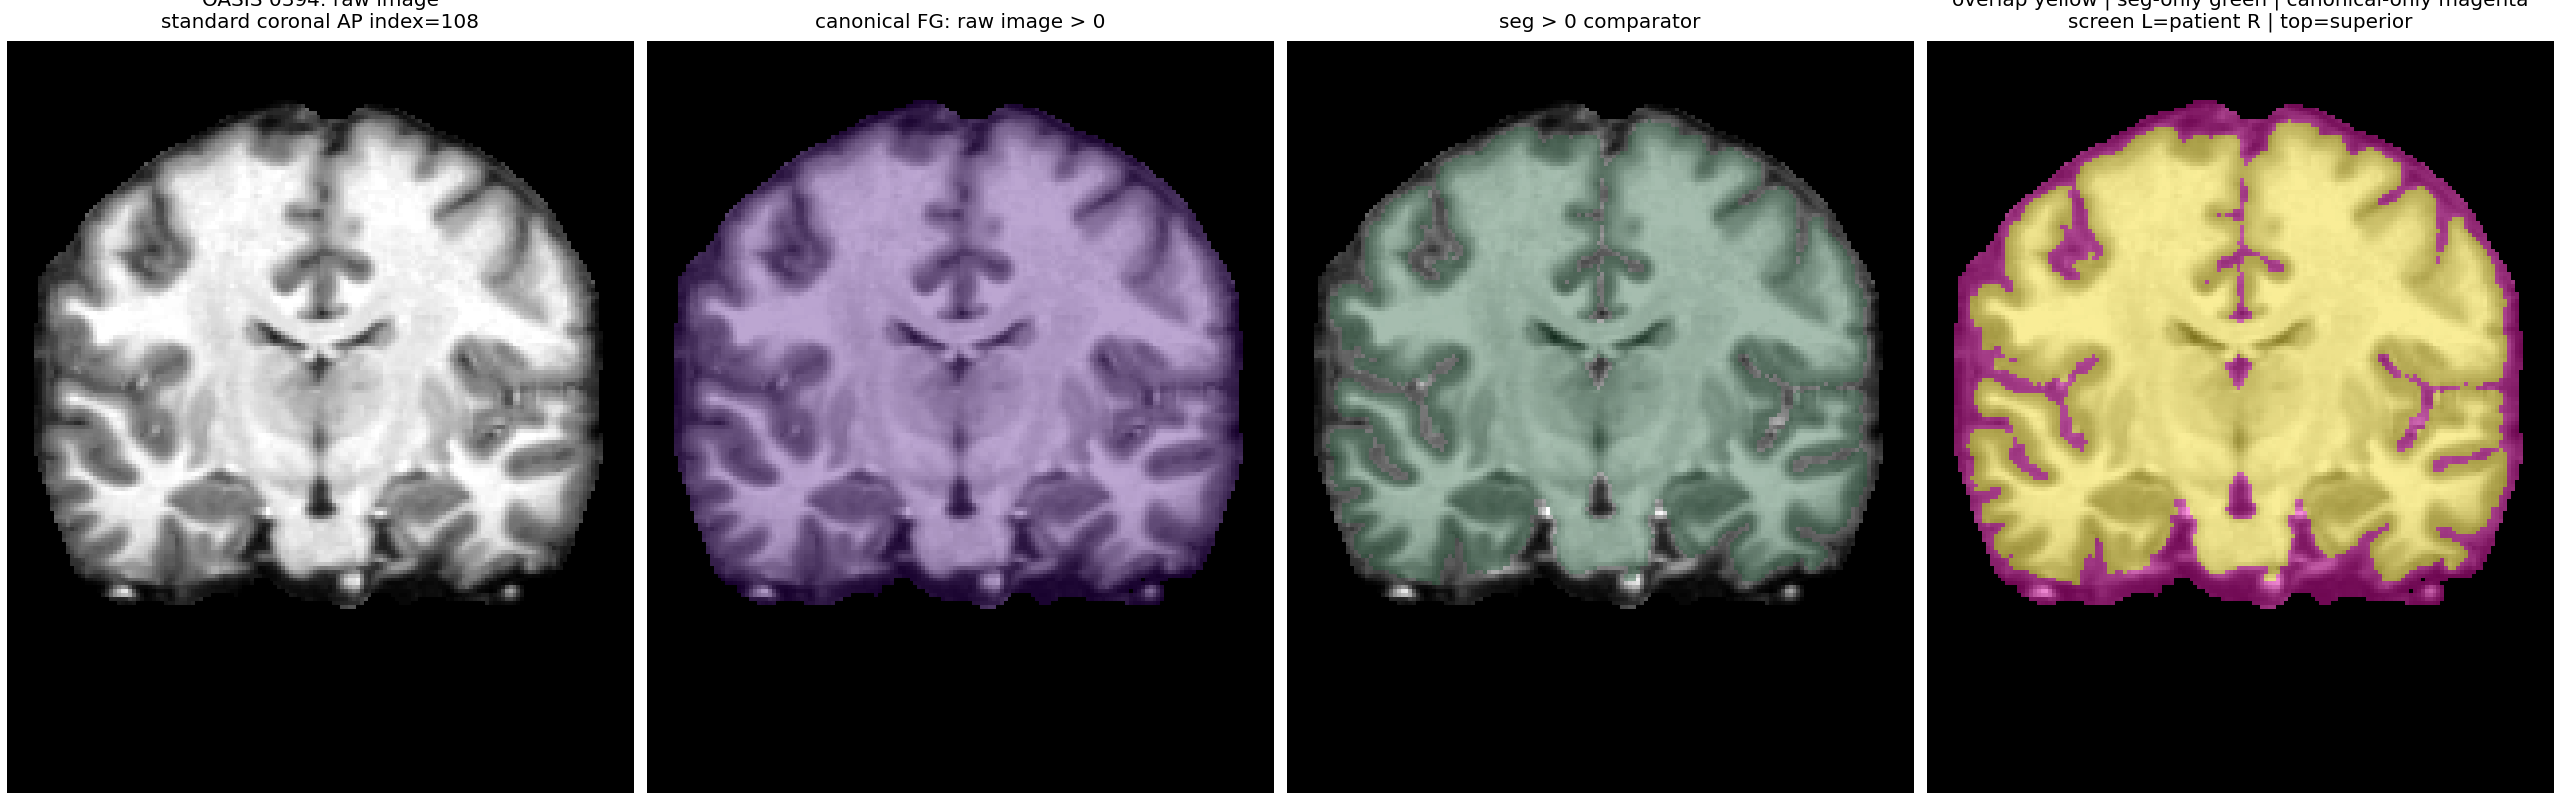

In [4]:
from IPython.display import Image, Markdown, display

for row in oasis_df.sort_values('subject_id').itertuples(index=False):
    display(Markdown(f"### OASIS {row.subject_id} | Dice {row.dice:.4f}"))
    fig_path = Path(row.figure)
    if not fig_path.is_absolute():
        fig_path = REPO / fig_path
    display(Image(filename=str(fig_path), width=1100))